# Why vibrations can locate objects: the data alone

No model in this notebook. We look at the exact input the src9 run `decres-rescale-aug10-v1` sees and ask, with numbers,
how much each factor (box, speaker, object, floor position) moves it, against the noise of re-recording the same scene.

**Feature (= the model's input).** Per capture: the 100 lasers' x/y pixel shifts, band-passed 100–1000 Hz, a 2% Tukey taper
(`--window tukey`), rfft, linear magnitude |X|, 100 lasers × 1170 bins × 2 channels, z-scored per sample over all
(laser, bin, channel) like the model (`process_x` + `Transformer4.Encoder`). FFT and train/eval split come from the run's own
`src9/dataset.py`.

**Base** = plastic box, speaker 1, candle, train split. Every figure changes one factor at a time from the base. Only train
levels are shown (train speakers 1/3/5/7, the 4 train objects); unseen objects appear only in §4 floor coverage.

Sections (each writes SVGs to its own folder under `figures/src/data_analysis/`):
1. `fft/` FFT magnitude per factor · 2. `variance/` change vs repeat noise · 3. `distance/` spectral vs floor distance ·
4. `floor_coverage/` where each object was recorded · 5. `resonance/` the box's resonance peak

In [1]:
BOX = "plastic"
SPEAKER = 1
OBJECT = "candle"
SPLIT = "train"

RUN = "decres-rescale-aug10-v1"
BOXES = ["gastro", "plastic", "cardboard"]
TRAIN_OBJECTS = ["candle", "red-cube", "soap dispenser", "vase"]   # the 4 single objects trained in every box
UNSEEN_OBJECTS = ["coffee pot", "tomato sauce"]
TRAIN_SPEAKERS = [1, 3, 5, 7]
MATCH_RADIUS = 0.05          # box fractions: "same position" in another box / with another object = nearest capture within this
NOISE_RADII = [3, 5, 10, 15, 25, 40]   # camera px: candidate radii for "same spot" in the repeat-noise baseline
NOISE_MIN_PAIRS = 30         # the noise radius is the smallest one with at least this many pairs
SMOOTH_HZ = 5.0              # display-only moving average of the full-band spectra in §1 (zooms and peaks use raw bins)
PEAK_LO = 120.0              # the dominant low resonance = argmax of a laser-averaged curve in PEAK_LO..PEAK_HI Hz
PEAK_HI = 260.0
FLOOR_BIN = 50               # camera px bins for §3

In [2]:
import sys
import json
import io
import contextlib
import itertools
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from scipy.stats import spearmanr
from scipy import ndimage

ROOT = Path.cwd().resolve()
while not (ROOT / "src9").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src9"))
sys.path.insert(0, str(ROOT / "figures/src"))
import dataset as D   # the run's own split + FFT code
import style

OUT = ROOT / "figures/src/data_analysis"
for sub in ["fft", "variance", "distance", "floor_coverage", "resonance"]:
    (OUT / sub).mkdir(parents=True, exist_ok=True)
CACHE = ROOT / "runs/_src9_cache/data_analysis"
CACHE.mkdir(parents=True, exist_ok=True)

ARGS = json.loads((ROOT / "runs" / RUN / "args.json").read_text())
assert ARGS["window"] == "tukey"

style.apply()   # matplotlib defaults + shared font sizes / line width

def save(fig, name):
    """name = '<section>/<file>' without extension"""
    path = OUT / f"{name}.svg"
    fig.savefig(path, bbox_inches="tight")
    print("saved", path.relative_to(ROOT))

## 0 · Dataset

Every sample of the run's three experiments, labelled with the split the run put it in (`train`, an `eval/<box>/<name>`
split, or `unused` = not in any split or dropped by `exclude.csv`). A sample's (r, c) is its object centre of mass in box
fractions of the cropped overhead photo; `r_px, c_px` the same in camera px (the crop is not rescaled, so px are one unit
across boxes). `coms` keeps every object's centre (multi-object scenes have two).

In [3]:
with contextlib.redirect_stdout(io.StringIO()):
    samples, idxs = D.load_splits()
dirs = list(samples.keys())
metas = list(samples.values())

split_of = ["unused"] * len(metas)
for name, ids in idxs.items():
    for i in ids:
        split_of[i] = name

BOX_NAME = {"gastronorm": "gastro", "green-plastic": "plastic", "cardboard": "cardboard"}
rows = []
for i, (d, m) in enumerate(zip(dirs, metas)):
    H, W = m["crop_overhead_shape"][:2]
    coms = np.array([c[0] for c in m["coms"]], np.float64).reshape(-1, 2)
    objects = "+".join(sorted(m["objects"])) if m["n_objects"] else "empty"
    has = len(coms) > 0
    rows.append(dict(
        i=i,
        dir=str(d),
        exp=m["experiment"],
        box=BOX_NAME[m["box"]],
        layout=m["layout"],
        pos=m["position_id"],
        spk=m["speaker"],
        objects=objects,
        n_objects=m["n_objects"],
        split=split_of[i],
        kind=split_of[i].split("/")[0],
        r=coms[:, 0].mean() / H if has else np.nan,
        c=coms[:, 1].mean() / W if has else np.nan,
        r_px=coms[:, 0].mean() if has else np.nan,
        c_px=coms[:, 1].mean() if has else np.nan,
        coms=[(rr / H, cc / W) for rr, cc in coms],
        t=pd.Timestamp(m["timestamp"]),
    ))
META = pd.DataFrame(rows)
print(len(META), "samples;", META.kind.value_counts().to_dict())

19119 samples; {'train': 11219, 'eval': 4672, 'unused': 3228}


In [4]:
# sample counts per box x object x speaker (any split) and train samples
counts = META.pivot_table(index=["box", "objects"], columns="spk", values="i", aggfunc="count", fill_value=0)
counts["total"] = counts.sum(axis=1)
counts["train"] = META[META.kind == "train"].groupby(["box", "objects"]).size().reindex(counts.index).fillna(0).astype(int)
with pd.option_context("display.max_rows", 200, "display.width", 200):
    print(counts.to_string())

# floor positions per box: a position is train if any of its captures is train, eval if any is eval (never both: the run's leak check)
pos_kind = META[META.kind != "unused"].groupby(["box", "exp", "pos"]).kind.agg(lambda k: "+".join(sorted(set(k))))
assert not (pos_kind == "eval+train").any()
print(pos_kind.reset_index().groupby(["box", "kind"]).size().unstack(fill_value=0).to_string())

spk                              1    2    3    4    5    7  total  train
box       objects                                                        
cardboard biscoff                9    0    9    0    9    9     36      0
          candle               289    0  289    0  289  289   1156    917
          coffee pot             9    0    9    0    9    9     36      0
          cylinder-1000g        34    0   34    0   34   34    136    107
          cylinder-100g         43    0   43    0   43   43    172    135
          cylinder-200g         49    0   49    0   49   49    196    153
          cylinder-500g         50    0   50    0   50   50    200    159
          empty                 22    0   22    0   22   22     88     73
          glass-cup             30    0   30    0   30   30    120     96
          green-cube+red-cube   98    0   98    0   98   98    392    309
          portable-charger      18    0   18    0   18   18     72      0
          red-cube             304    

In [5]:
# floor regions (used by §1 position and §2 position): per box a circle at the centre of each quadrant of the base grid
# (speaker 1, candle, train; object-centre extent split at its midpoint). Centres + radius live in style.py; re-derived and checked here.
REGION_NAMES = style.REGION_NAMES
for b in BOXES:
    g = META[(META.box == b) & (META.spk == SPEAKER) & (META.objects == OBJECT) & (META.kind == SPLIT)]
    r0 = g.r.min()
    r1 = g.r.max()
    c0 = g.c.min()
    c1 = g.c.max()
    rm = (r0 + r1) / 2
    cm = (c0 + c1) / 2
    centres = {
        "top-left": ((r0 + rm) / 2, (c0 + cm) / 2),
        "top-right": ((r0 + rm) / 2, (cm + c1) / 2),
        "bottom-left": ((rm + r1) / 2, (c0 + cm) / 2),
        "bottom-right": ((rm + r1) / 2, (cm + c1) / 2),
    }
    for name in REGION_NAMES:
        assert np.allclose(centres[name], style.REGION_CENTRES[b][name], atol=1e-3), (b, name)

META["region"] = [style.region_of(r, c, b) if r == r else None for r, c, b in zip(META.r, META.c, META.box)]
BASE = META[(META.box == BOX) & (META.spk == SPEAKER) & (META.objects == OBJECT) & (META.kind == SPLIT)].reset_index(drop=True)
print(f"base = ({BOX}, speaker {SPEAKER}, {OBJECT}, {SPLIT}): {len(BASE)} captures")
print("base captures per region:", BASE.region.value_counts().reindex(REGION_NAMES).to_dict())

base = (plastic, speaker 1, candle, train): 202 captures
base captures per region: {'top-left': 16, 'top-right': 17, 'bottom-left': 18, 'bottom-right': 23}


In [6]:
# photos: an empty-box photo per box, and a crop around each train object (from a base-box speaker-1 capture)
def photo(d, height=None):
    image = Image.open(Path(d) / "image/02_cropped_overhead.png").convert("RGB")
    if height is not None:
        image = image.resize((round(image.width * height / image.height), height), Image.LANCZOS)
    return np.asarray(image)

def mask_of(d):
    return np.asarray(Image.open(Path(d) / "image/03_smask.png").convert("L")) > 127

def object_crop(d, mask, margin=0.35, size=160):
    image = photo(d)
    rr, cc = np.where(mask)
    side = int(max(rr.max() - rr.min(), cc.max() - cc.min()) * (1 + 2 * margin)) // 2
    rm = (rr.max() + rr.min()) // 2
    cm = (cc.max() + cc.min()) // 2
    crop = image[max(rm - side, 0):rm + side, max(cm - side, 0):cm + side]
    return np.asarray(Image.fromarray(crop).resize((size, size), Image.LANCZOS))

def central_sample(objects, box=None):
    """the capture of this object (speaker 1) closest to the floor centre whose mask is sane (some saved masks cover the whole photo)"""
    pick = META[(META.objects == objects) & (META.spk == SPEAKER)]
    if box is not None and (pick.box == box).any():
        pick = pick[pick.box == box]
    pick = pick.assign(dm=(pick.r - 0.5) ** 2 + (pick.c - 0.5) ** 2).sort_values("dm")
    for d in pick.dir:
        mask = mask_of(d)
        if 0 < mask.mean() < 0.05:
            return d, mask
    raise ValueError(objects)

BOX_PHOTO = {}
for b in BOXES:
    d = META[(META.box == b) & (META.objects == "empty") & (META.kind == "train")].sort_values("t").dir.iloc[0]
    BOX_PHOTO[b] = photo(d, 360)

OBJECT_PHOTO = {}
for o in TRAIN_OBJECTS:
    d, mask = central_sample(o, BOX)
    OBJECT_PHOTO[o] = object_crop(d, mask)

## Features (cached)

The z-scored |X| of every capture used below, float16 memmap (N, 100 lasers, 1170 bins, 2) in `runs/_src9_cache/data_analysis/`,
plus each capture's laser-averaged curve (mean over lasers and channels, 1170 bins). Spectral distance between two captures
= **cosine distance d = 1 − cos(z_a, z_b)** on the full feature. Each z has mean 0 and variance 1, so cos = Pearson ρ and the
mean squared difference is exactly 2d: ratios of d are ratios of mean squared difference.

In [7]:
NEED = META[
    ((META.kind == "train") & (META.spk == SPEAKER) & META.objects.isin(TRAIN_OBJECTS))
    | ((META.kind == "train") & (META.box == BOX) & (META.objects == OBJECT))
    | ((META.kind == "train") & (META.objects == "empty"))
    | ((META.kind != "unused") & (META.spk == SPEAKER) & META.objects.isin(UNSEEN_OBJECTS))
    | ((META.kind != "unused") & (META.box == BOX) & (META.layout == "cube-5-speakers"))
].reset_index(drop=True)   # unchanged from the cached set (unseen + cube-5 rows are cached but no longer used)

def features(d, meta):
    x = D.load_fft(Path(d), meta, "tukey").abs().numpy()
    return (x - x.mean()) / (x.std() + 1e-6)

index_file = CACHE / "feats_index.parquet"
feats_file = CACHE / "feats.npy"
curves_file = CACHE / "curves.npy"
cached = pd.read_parquet(index_file) if index_file.exists() else None
if cached is None or set(cached.dir) != set(NEED.dir):
    L, F, C = 100, 1170, 2
    out = np.lib.format.open_memmap(feats_file, mode="w+", dtype=np.float16, shape=(len(NEED), L, F, C))
    curves = np.zeros((len(NEED), F), np.float32)
    for k, d in enumerate(NEED.dir):
        z = features(d, samples[Path(d)])
        out[k] = z.astype(np.float16)
        curves[k] = z.mean((0, 2))
    out.flush()
    del out
    np.save(curves_file, curves)
    NEED[["dir"]].to_parquet(index_file)
    cached = NEED[["dir"]]
FEATS = np.load(feats_file, mmap_mode="r")
CURVES = np.load(curves_file)
ROW = {d: k for k, d in enumerate(cached.dir)}
META["row"] = META.dir.map(ROW)
BASE["row"] = BASE.dir.map(ROW)

m0 = samples[Path(NEED.dir[0])]
T = np.load(Path(NEED.dir[0]) / "vibration/02_raw_shifts.npy", mmap_mode="r").shape[1]
f_all = np.fft.rfftfreq(T, 1 / float(m0["fps"]))
FREQ = f_all[(f_all >= float(m0["min_freq"])) & (f_all <= float(m0["max_freq"]))]
DF = FREQ[1] - FREQ[0]
print(f"{FEATS.shape}, {FREQ[0]:.0f}-{FREQ[-1]:.0f} Hz, {DF:.3f} Hz/bin")

def group(box=BOX, spk=SPEAKER, objects=OBJECT, kind=SPLIT):
    """the captures of one (box, speaker, object, split) cell, with their cache row"""
    g = META[(META.box == box) & (META.spk == spk) & (META.objects == objects) & (META.kind == kind)]
    assert g.row.notna().all(), "capture not in the feature cache"
    g = g.reset_index(drop=True)
    g["row"] = g.row.astype(int)
    return g

def unit_features(rows):
    """full features of these cache rows, (n, L*F*C) float32, each scaled to unit length"""
    Z = np.stack([np.asarray(FEATS[r], np.float32).ravel() for r in rows])
    Z /= np.linalg.norm(Z, axis=1, keepdims=True)
    return Z

def cos_dist(a, b=None):
    """1 - cos for every capture of DataFrame a against every capture of b (default: a itself)"""
    Za = unit_features(a.row.values)
    Zb = Za if b is None else unit_features(b.row.values)
    return 1.0 - Za @ Zb.T

def floor_px(a, b):
    """floor distance between object centres, camera px, every a against every b"""
    dr = a.r_px.values[:, None] - b.r_px.values[None, :]
    dc = a.c_px.values[:, None] - b.c_px.values[None, :]
    return np.sqrt(dr ** 2 + dc ** 2)

def floor_frac(a, b):
    """floor distance in box fractions (comparable across boxes of different size)"""
    dr = a.r.values[:, None] - b.r.values[None, :]
    dc = a.c.values[:, None] - b.c.values[None, :]
    return np.sqrt(dr ** 2 + dc ** 2)

(3573, 100, 1170, 2), 101-1000 Hz, 0.769 Hz/bin


## Repeat noise baseline (used by §2 and §3)

The noise of recording **the same scene again later**: pairs of base captures (plastic, speaker 1, candle, train) whose object
centres are within R camera px of each other. Two captures are never at the same moment, so every such pair is a re-recording
(minutes to days apart). R is the smallest radius in `NOISE_RADII` with at least `NOISE_MIN_PAIRS` pairs.

In [8]:
D_BASE = cos_dist(BASE)
PX_BASE = floor_px(BASE, BASE)
iu, ju = np.triu_indices(len(BASE), 1)
base_pairs = pd.DataFrame(dict(
    a=iu,
    b=ju,
    d=D_BASE[iu, ju],
    px=PX_BASE[iu, ju],
    same_layout=BASE.layout.values[iu] == BASE.layout.values[ju],
    minutes=np.abs((BASE.t.values[iu] - BASE.t.values[ju]) / np.timedelta64(1, "m")),
))
H_BASE, W_BASE = samples[Path(BASE.dir[0])]["crop_overhead_shape"][:2]

radius_rows = []
for R in NOISE_RADII:
    p = base_pairs[base_pairs.px <= R]
    radius_rows.append(dict(
        R_px=R,
        mask_px=f"{R * 64 / H_BASE:.2f} x {R * 64 / W_BASE:.2f}",
        pairs=len(p),
        same_layout=int(p.same_layout.sum()),
        median_minutes=p.minutes.median(),
        mean_d=p.d.mean(),
    ))
NOISE_RADIUS_TABLE = pd.DataFrame(radius_rows)
print(NOISE_RADIUS_TABLE.round(4).to_string(index=False))
NOISE_R = min(R for R in NOISE_RADII if (base_pairs.px <= R).sum() >= NOISE_MIN_PAIRS)
NOISE_PAIRS = base_pairs[base_pairs.px <= NOISE_R]
NOISE = NOISE_PAIRS.d.mean()
print(f"noise radius R = {NOISE_R} px; {len(NOISE_PAIRS)} pairs; noise d = {NOISE:.5f} (rho = {1 - NOISE:.4f}), std {NOISE_PAIRS.d.std():.5f}")

 R_px     mask_px  pairs  same_layout  median_minutes  mean_d
    3 0.19 x 0.15     10            0         49.2872  0.0236
    5 0.32 x 0.24     20            0         48.6085  0.0232
   10 0.63 x 0.49     40            0         48.6631  0.0282
   15 0.95 x 0.73     65            1         48.9722  0.0313
   25 1.58 x 1.22    111            3         49.0606  0.0379
   40 2.53 x 1.95    211           27         48.6222  0.0415
noise radius R = 10 px; 40 pairs; noise d = 0.02816 (rho = 0.9718), std 0.02266


## 1 · FFT magnitude, one factor at a time

One panel per factor, everything else at the base. Curve = mean over captures of the laser-averaged z|X| (5 Hz display
smoothing); black = per-bin median across the level curves. Right: zoom on the dominant low resonance at full resolution
(0.77 Hz bins), each curve's peak (argmax in 120–260 Hz) dotted and labelled.
Levels: box = 3 boxes; speaker = train speakers 1/3/5/7; object = 4 train objects (speaker 1); position = the base captures
inside each of the 4 floor regions (§0).

saved figures/src/data_analysis/fft/fft_all.svg


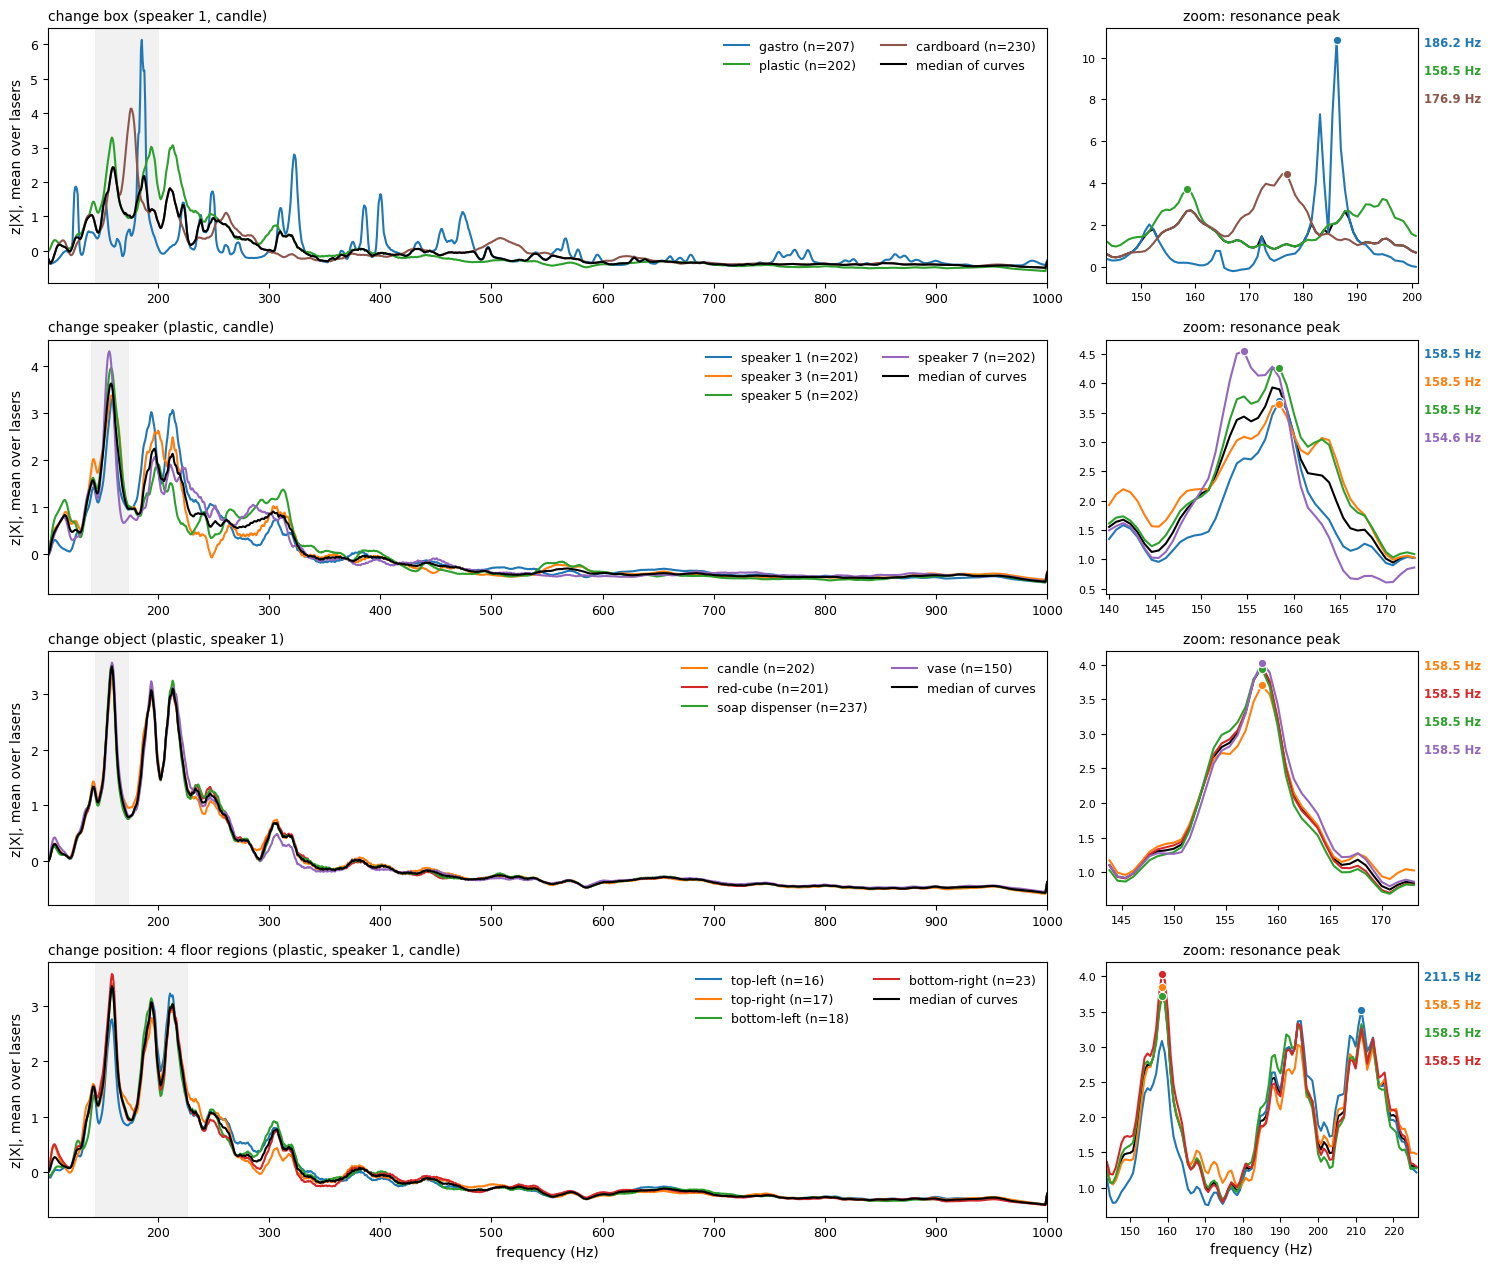

saved figures/src/data_analysis/fft/fft_box.svg
saved figures/src/data_analysis/fft/fft_speaker.svg
saved figures/src/data_analysis/fft/fft_object.svg


saved figures/src/data_analysis/fft/fft_position.svg
  factor          level   n  peak
     box         gastro 207 186.2
     box        plastic 202 158.5
     box      cardboard 230 176.9
 speaker      speaker 1 202 158.5
 speaker      speaker 3 201 158.5
 speaker      speaker 5 202 158.5
 speaker      speaker 7 202 154.6
  object         candle 202 158.5
  object       red-cube 201 158.5
  object soap dispenser 237 158.5
  object           vase 150 158.5
position       top-left  16 211.5
position      top-right  17 158.5
position    bottom-left  18 158.5
position   bottom-right  23 158.5


In [9]:
def smooth(y):
    k = max(int(round(SMOOTH_HZ / DF)), 1)
    return np.convolve(y, np.ones(k) / k, mode="same")

def peak_hz(curve):
    keep = (FREQ >= PEAK_LO) & (FREQ <= PEAK_HI)
    return float(FREQ[keep][np.argmax(curve[keep])])

def region_rows(name):
    return BASE[BASE.region == name]

FFT_LEVELS = {   # factor -> [(label, captures, colour)]
    "box": [(b, group(box=b), style.BOX_COLORS[b]) for b in BOXES],
    "speaker": [(f"speaker {s}", group(spk=s), style.SPEAKER_COLORS[s]) for s in TRAIN_SPEAKERS],
    "object": [(o, group(objects=o), style.OBJECT_COLORS[o]) for o in TRAIN_OBJECTS],
    "position": [(name, region_rows(name), style.POSITION_COLORS[name]) for name in REGION_NAMES],
}
FFT_TITLES = {
    "box": f"change box (speaker {SPEAKER}, {OBJECT})",
    "speaker": f"change speaker ({BOX}, {OBJECT})",
    "object": f"change object ({BOX}, speaker {SPEAKER})",
    "position": f"change position: 4 floor regions ({BOX}, speaker {SPEAKER}, {OBJECT})",
}

FFT_PEAKS = []
def fft_panel(ax, zax, factor):
    means = []
    for label, g, color in FFT_LEVELS[factor]:
        mean = CURVES[g.row.values.astype(int)].mean(0)
        means.append(mean)
        ax.plot(FREQ, smooth(mean), color=color, lw=style.LW, label=f"{label} (n={len(g)})")
        FFT_PEAKS.append(dict(factor=factor, level=label, n=len(g), peak=peak_hz(mean)))
    median = np.median(np.stack(means), 0)
    ax.plot(FREQ, smooth(median), color=style.MEDIAN_COLOR, lw=style.LW, label="median of curves")
    peaks = [peak_hz(m) for m in means]
    lo = min(peaks) - 15
    hi = max(peaks) + 15
    ax.axvspan(lo, hi, color=style.NOISE_COLOR, alpha=0.1, lw=0)
    ax.set_xlim(FREQ[0], FREQ[-1])
    ax.set_ylabel("z|X|, mean over lasers")
    ax.set_title(FFT_TITLES[factor], loc="left")
    ax.legend(loc="upper right", frameon=False, ncol=2)

    keep = (FREQ >= lo) & (FREQ <= hi)
    zax.plot(FREQ[keep], median[keep], color=style.MEDIAN_COLOR, lw=style.LW)
    for k, ((label, g, color), mean, f0) in enumerate(zip(FFT_LEVELS[factor], means, peaks)):
        zax.plot(FREQ[keep], mean[keep], color=color, lw=style.LW)
        y0 = mean[np.argmin(np.abs(FREQ - f0))]
        zax.plot(f0, y0, marker="o", ms=6, color=color, mec="white", mew=0.8, ls="none", zorder=5)
        zax.text(1.02, 0.97 - 0.11 * k, f"{f0:.1f} Hz", transform=zax.transAxes, color=color, fontsize="small", va="top", fontweight="bold")
    zax.set_xlim(lo, hi)
    zax.set_title("zoom: resonance peak")
    zax.tick_params(labelsize=8)

def fft_figure(factors, name):
    fig, axes = plt.subplots(len(factors), 2, figsize=(style.WIDE, 3.2 * len(factors)), gridspec_kw=dict(width_ratios=[3.2, 1]), squeeze=False)
    for (ax, zax), factor in zip(axes, factors):
        fft_panel(ax, zax, factor)
    axes[-1, 0].set_xlabel("frequency (Hz)")
    axes[-1, 1].set_xlabel("frequency (Hz)")
    fig.tight_layout()
    save(fig, name)
    return fig

FFT_FACTORS = ["box", "speaker", "object", "position"]
fft_figure(FFT_FACTORS, "fft/fft_all")
plt.show()
for factor in FFT_FACTORS:
    fig = fft_figure([factor], f"fft/fft_{factor}")
    plt.close(fig)
FFT_PEAKS = pd.DataFrame(FFT_PEAKS).drop_duplicates(["factor", "level"])
print(FFT_PEAKS.round(1).to_string(index=False))

In [10]:
# how far the level curves sit apart in the laser-averaged spectrum, against the repeat noise of the same curve
# (R = mean over bins of the variance between level means / mean over bins of half the squared difference of noise-pair curves)
noise_curve_var = ((CURVES[BASE.row.values[NOISE_PAIRS.a.values]] - CURVES[BASE.row.values[NOISE_PAIRS.b.values]]) ** 2 / 2).mean(0)
FFT_R = {}
for factor in FFT_FACTORS:
    means = np.stack([CURVES[g.row.values.astype(int)].mean(0) for _, g, _ in FFT_LEVELS[factor]])
    FFT_R[factor] = float(means.var(0).mean() / noise_curve_var.mean())
print("between-level variance of the laser-averaged spectrum / repeat noise:", {k: round(v, 1) for k, v in FFT_R.items()})

between-level variance of the laser-averaged spectrum / repeat noise: {'box': 16.8, 'speaker': 3.4, 'object': 0.2, 'position': 0.6}


**Reading §1**
- **Box** moves the laser-averaged spectrum most: the level means differ by **16.8×** the repeat-noise variance of the same curve. Each box has its own dominant low peak: **gastro 186.2, cardboard 176.9, plastic 158.5 Hz**.
- **Speaker** comes next at **3.4×**. Speakers 1 / 3 / 5 peak at **158.5 Hz**; speaker 7 at **154.6 Hz**.
- **Object (0.2×)** and **position (0.6×)** leave the laser-averaged spectrum at the noise level. All 4 objects peak at **158.5 Hz**.
- Position changes which plastic resonance is loudest, not where it is: the top-left region peaks at **211.5 Hz**, the other three at **158.5 Hz**. The 211.5 Hz hump is present in every region (zoom).
- So the *average* spectrum identifies the box, a little the speaker, and almost nothing about object or position. That information has to sit in how the spectrum is spread over the 100 lasers (§2, §3).

## 2 · Change relative to repeat noise

Each bar = mean cosine distance d over matched pairs ÷ the repeat noise (same spot re-recorded, R px), so noise = 1×.
Every pair starts from a base capture a and changes exactly one factor:
- **box**: a vs the nearest-position (≤ 0.05 box fraction) candle capture, speaker 1, train, in the other box.
- **speaker**: a vs the same position (same `position_id`, seconds apart) with speaker 3 / 5 / 7.
- **object**: a vs the nearest-position (≤ 0.05) capture of red-cube / soap dispenser / vase, plastic, speaker 1, train.
- **position**: every pair of base captures in *different* floor regions (6 region pairs).

Error bars = ±1 std over pairs. The `variance_<factor>` figures split each bar by level.

In [11]:
def nearest_pairs(a, b):
    """for each capture of a, the nearest-position capture of b within MATCH_RADIUS: (d, floor match) per matched a"""
    d = cos_dist(a, b)
    frac = floor_frac(a, b)
    k = frac.argmin(1)
    ok = frac[np.arange(len(a)), k] <= MATCH_RADIUS
    return d[np.arange(len(a)), k][ok], frac[np.arange(len(a)), k][ok]

pairs = []
for b in BOXES:
    if b == BOX:
        continue
    d, match = nearest_pairs(BASE, group(box=b))
    pairs += [dict(factor="box", level=b, d=x, match=m) for x, m in zip(d, match)]
for s in TRAIN_SPEAKERS[1:]:
    other = group(spk=s)
    key = other.set_index(["exp", "pos"]).row
    both = BASE[BASE.set_index(["exp", "pos"]).index.isin(key.index)].reset_index(drop=True)
    other = other.set_index(["exp", "pos"]).loc[list(zip(both.exp, both.pos))].reset_index()
    d = 1.0 - (unit_features(both.row.values) * unit_features(other.row.values)).sum(1)
    pairs += [dict(factor="speaker", level=f"speaker {s}", d=x, match=0.0) for x in d]
for o in TRAIN_OBJECTS[1:]:
    d, match = nearest_pairs(BASE, group(objects=o))
    pairs += [dict(factor="object", level=o, d=x, match=m) for x, m in zip(d, match)]
reg = BASE.region.values
for i, j, d in zip(base_pairs.a, base_pairs.b, base_pairs.d):
    if pd.isna(reg[i]) or pd.isna(reg[j]) or reg[i] == reg[j]:
        continue
    first, second = sorted([reg[i], reg[j]], key=REGION_NAMES.index)
    pairs.append(dict(factor="position", level=f"{first} | {second}", d=d, match=np.nan))
pairs += [dict(factor="noise", level=f"same spot (≤{NOISE_R} px)", d=x, match=np.nan) for x in NOISE_PAIRS.d]
PAIRS = pd.DataFrame(pairs)
PAIRS["ratio"] = PAIRS.d / NOISE
SUMMARY = PAIRS.groupby("factor").ratio.agg(["size", "mean", "std", "median"]).reindex(["noise", "box", "speaker", "object", "position"])
SUMMARY["match_median"] = PAIRS.groupby("factor").match.median()
print(SUMMARY.round(2).to_string())
LEVELS = PAIRS.groupby(["factor", "level"], sort=False).ratio.agg(["size", "mean", "std"])
print(LEVELS.round(2).to_string())

          size   mean   std  median  match_median
factor                                           
noise       40   1.00  0.80    0.70           NaN
box        403  22.11  3.07   20.73          0.02
speaker    605   6.49  1.38    6.31          0.00
object     557   2.21  0.87    2.06          0.02
position  2039   3.67  1.05    3.53           NaN
                                     size   mean   std
factor   level                                        
box      gastro                       201  25.08  0.84
         cardboard                    202  19.16  0.74
speaker  speaker 3                    201   5.28  0.69
         speaker 5                    202   7.91  1.01
         speaker 7                    202   6.28  0.84
object   red-cube                     202   2.09  0.85
         soap dispenser               202   2.28  0.91
         vase                         153   2.27  0.82
position top-right | bottom-right     391   3.34  0.93
         top-left | bottom-right      368   4

saved figures/src/data_analysis/variance/variance_all.svg


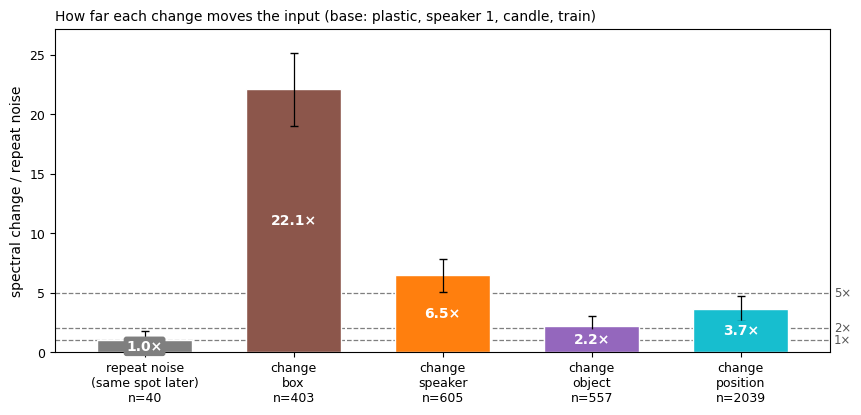

In [12]:
def bars(ax, labels, values, stds, colors, ns):
    """one bar per level; value written inside the bar, n under the tick label, dashed 1x / 2x / 5x reference lines"""
    xs = np.arange(len(labels))
    top = max(v + s for v, s in zip(values, stds)) * 1.08
    for x, v, s, c in zip(xs, values, stds, colors):
        if isinstance(c, tuple):   # two colours = a bar split in half (position: the two regions of the pair)
            ax.bar(x - 0.16, v, width=0.32, color=c[0], edgecolor="white", lw=1)
            ax.bar(x + 0.16, v, width=0.32, color=c[1], edgecolor="white", lw=1)
            box_color = style.INK
        else:
            ax.bar(x, v, width=0.64, color=c, edgecolor="white", lw=1)
            box_color = c
        ax.errorbar(x, v, yerr=s, color=style.INK, capsize=3, lw=0.9, zorder=3)
        ax.text(x, v / 2, f"{v:.1f}×", ha="center", va="center", fontweight="bold", color="white", zorder=4,
                bbox=dict(boxstyle="round,pad=0.2", facecolor=box_color, edgecolor="none"))
    for ref in [1, 2, 5]:
        if ref < top:
            ax.axhline(ref, color=style.NOISE_COLOR, ls="--", lw=0.9, zorder=0)
            ax.text(1.005, ref, f"{ref}×", transform=ax.get_yaxis_transform(), va="center", ha="left", fontsize="small", color=style.MUTED)
    ax.set_xticks(xs)
    ax.set_xticklabels([f"{l}\nn={n}" for l, n in zip(labels, ns)])
    ax.set_xlim(-0.6, len(labels) - 0.4)
    ax.set_ylim(0, top)
    ax.set_ylabel("spectral change / repeat noise")

FACTORS = ["box", "speaker", "object", "position"]
fig, ax = plt.subplots(figsize=(style.NARROW, 4.2))
order = ["noise"] + FACTORS
bars(ax,
     ["repeat noise\n(same spot later)", "change\nbox", "change\nspeaker", "change\nobject", "change\nposition"],
     SUMMARY.loc[order, "mean"].values,
     SUMMARY.loc[order, "std"].values,
     [style.FACTOR_COLORS[f] for f in order],
     SUMMARY.loc[order, "size"].astype(int).values)
ax.set_title(f"How far each change moves the input (base: {BOX}, speaker {SPEAKER}, {OBJECT}, {SPLIT})", loc="left")
save(fig, "variance/variance_all")
plt.show()

saved figures/src/data_analysis/variance/variance_box.svg


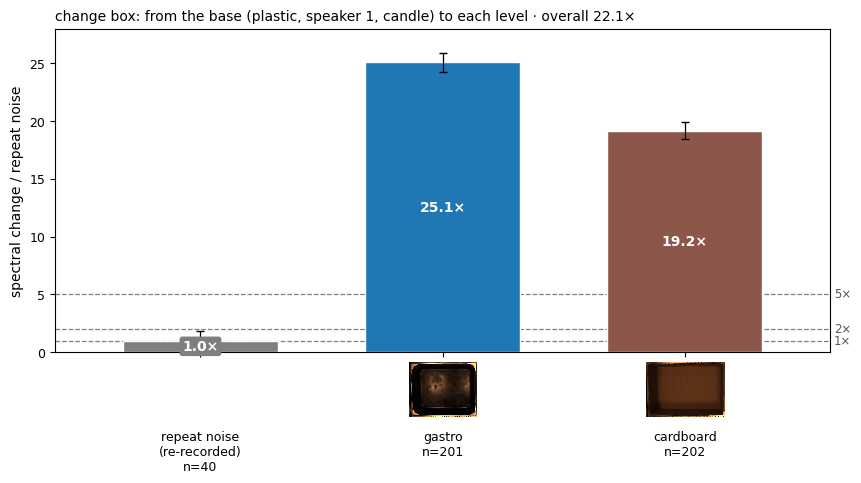

saved figures/src/data_analysis/variance/variance_speaker.svg


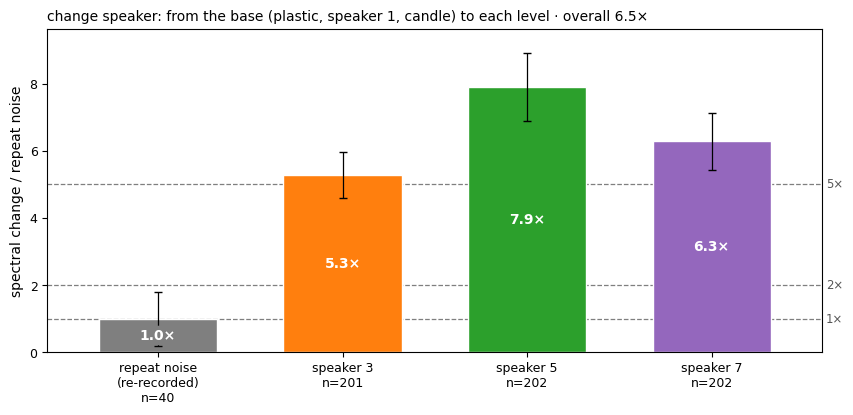

saved figures/src/data_analysis/variance/variance_object.svg


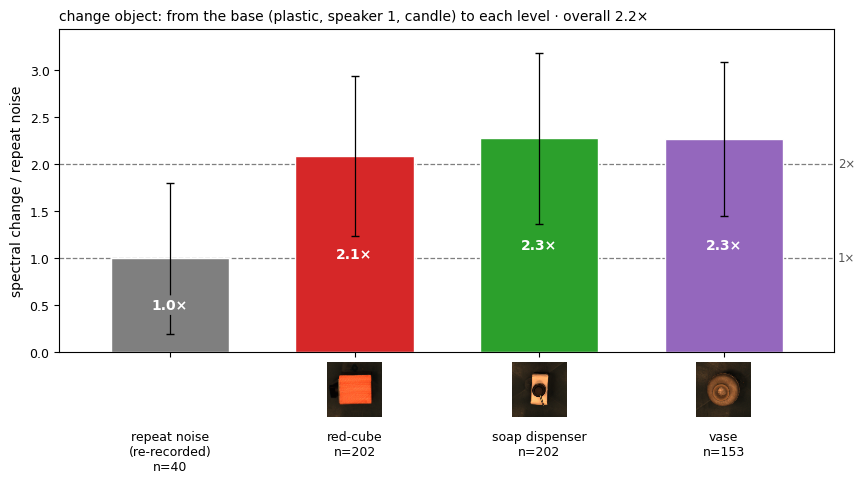

saved figures/src/data_analysis/variance/variance_position.svg


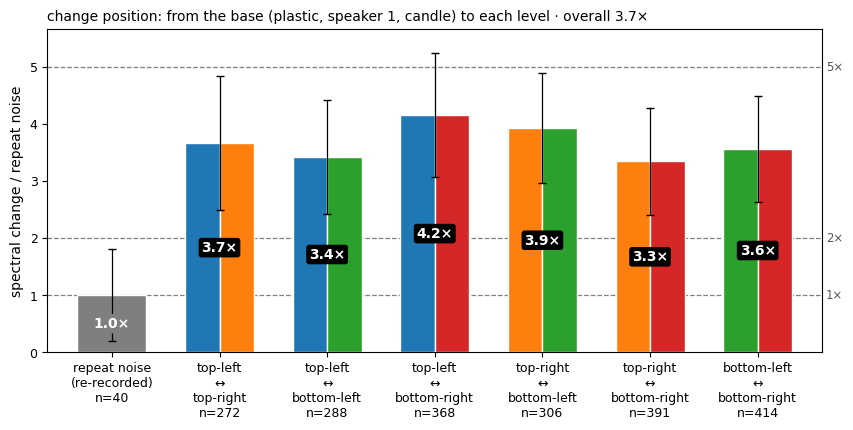

In [13]:
LEVEL_COLORS = {
    "noise": lambda l: style.FACTOR_COLORS["noise"],
    "box": lambda l: style.BOX_COLORS[l],
    "speaker": lambda l: style.SPEAKER_COLORS[int(l.split()[-1])],
    "object": lambda l: style.OBJECT_COLORS[l],
    "position": lambda l: (style.POSITION_COLORS[l.split(" | ")[0]], style.POSITION_COLORS[l.split(" | ")[1]]),
}
LEVEL_IMAGES = {
    "box": lambda l: BOX_PHOTO[l],
    "object": lambda l: OBJECT_PHOTO[l],
}
for factor in FACTORS:
    t = LEVELS.loc[factor]
    if factor == "position":
        t = t.reindex([f"{a} | {b}" for a, b in itertools.combinations(REGION_NAMES, 2)])
    t = pd.concat([LEVELS.loc[["noise"]].droplevel(0), t])
    labels = list(t.index)
    fig, ax = plt.subplots(figsize=(style.NARROW, 4.2))
    tick_labels = ["repeat noise\n(re-recorded)"] + [l.replace(" | ", "\n↔\n") for l in labels[1:]]
    colors = [LEVEL_COLORS["noise"](labels[0])] + [LEVEL_COLORS[factor](l) for l in labels[1:]]
    bars(ax, tick_labels, t["mean"].values, t["std"].values, colors, t["size"].astype(int).values)
    ax.set_title(f"change {factor}: from the base ({BOX}, speaker {SPEAKER}, {OBJECT}) to each level · overall {SUMMARY.loc[factor, 'mean']:.1f}×", loc="left")
    if factor in LEVEL_IMAGES:
        style.image_ticks(ax, [None] + [LEVEL_IMAGES[factor](l) for l in labels[1:]], size=0.55)
    save(fig, f"variance/variance_{factor}")
    plt.show()

**Reading §2**
- Repeat noise (same spot, ≤ **10 px** = 0.6 × 0.5 mask px, **40** pairs, all from different layouts, median **49 min** apart): d = **0.0282** (ρ = 0.972). Its spread is large (std **0.80×** its mean). The radius table: 3 px gives only 10 pairs, 5 px 20, 10 px 40. Mean d rises with R (0.024 at 3 px, 0.038 at 25 px), so part of this baseline is still sub-pixel position change.
- Ordering: **box 22.1× > speaker 6.5× > position 3.7× > object 2.2× > noise 1×** (n = 403 / 605 / 2,039 / 557 / 40 pairs).
- **Box**: gastro **25.1×**, cardboard **19.2×** from plastic.
- **Speaker**: speaker 5 is the furthest (**7.9×**), then 7 (**6.3×**), then 3 (**5.3×**). Changing the speaker moves the input **1.8×** more than moving the object to another floor region (6.5 vs 3.7). The model must ignore a bigger change than the one it reads.
- **Object**: every object is about equally far from the candle: red-cube **2.1×**, soap dispenser **2.3×**, vase **2.3×**. Only about twice the re-recording noise, with matched positions ≤ 0.05 box fraction apart (median **0.02**).
- **Position**: the 6 region pairs span **3.3–4.2×**. The diagonal top-left ↔ bottom-right pair is the largest (**4.2×**); top-right ↔ bottom-right the smallest (**3.3×**).

## 3 · Spectral distance vs floor distance

x = floor distance between the two object centres (camera px); y = cosine distance d of the full feature. Lines = mean ± std in
50 px bins (bins with ≥ 10 pairs). Dashed grey = the repeat noise (§2).
- `distance_all`: pairs within the base, and pairs (base capture, capture that differs in exactly one factor): box → the other two
  boxes, object → the other 3 train objects, speaker → speakers 3/5/7. Floor distance is still between the two object centres.
- `distance_box` / `distance_object` / `distance_speaker`: one line per level, pairs within that level
  (box: speaker 1, candle; object: plastic, speaker 1; speaker: plastic, candle).

saved figures/src/data_analysis/distance/distance_all.svg


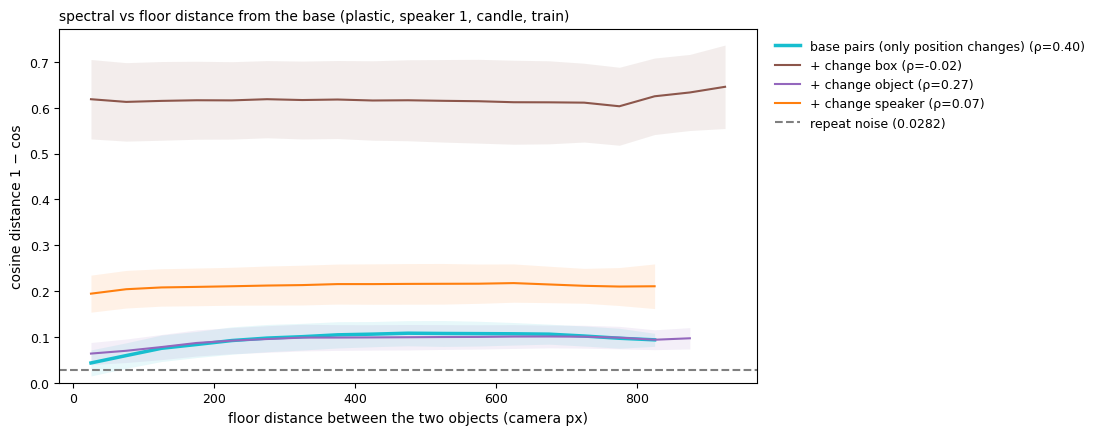

In [14]:
def binned(px, d):
    edges = np.arange(0, px.max() + FLOOR_BIN, FLOOR_BIN)
    k = np.digitize(px, edges) - 1
    out = pd.DataFrame(dict(bin=k, d=d)).groupby("bin").d.agg(["mean", "std", "size"])
    out = out[out["size"] >= 10]
    out["px"] = edges[out.index] + FLOOR_BIN / 2
    return out

def within(g):
    iu, ju = np.triu_indices(len(g), 1)
    return floor_px(g, g)[iu, ju], cos_dist(g)[iu, ju]

def across(a, b):
    return floor_px(a, b).ravel(), cos_dist(a, b).ravel()

def line(ax, px, d, color, label, lw=style.LW):
    c = binned(px, d)
    rho = spearmanr(px, d).statistic
    ax.plot(c.px, c["mean"], color=color, lw=lw, label=f"{label} (ρ={rho:.2f})")
    ax.fill_between(c.px, c["mean"] - c["std"], c["mean"] + c["std"], color=color, alpha=0.1, lw=0)
    return c

def finish(ax, title):
    ax.axhline(NOISE, color=style.NOISE_COLOR, ls="--", lw=style.LW, label=f"repeat noise ({NOISE:.4f})")
    ax.set_xlabel("floor distance between the two objects (camera px)")
    ax.set_ylabel("cosine distance 1 − cos")
    ax.set_ylim(0, None)
    ax.set_title(title, loc="left")
    ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1.0))

DIST_CURVES = {}
fig, ax = plt.subplots(figsize=(9, 4.6))
DIST_CURVES[("all", "base")] = line(ax, base_pairs.px.values, base_pairs.d.values, style.FACTOR_COLORS["position"], "base pairs (only position changes)", lw=style.LW_BASE)
px = []
d = []
for b in BOXES:
    if b != BOX:
        x, y = across(BASE, group(box=b))
        px.append(x)
        d.append(y)
DIST_CURVES[("all", "box")] = line(ax, np.concatenate(px), np.concatenate(d), style.FACTOR_COLORS["box"], "+ change box")
px = []
d = []
for o in TRAIN_OBJECTS[1:]:
    x, y = across(BASE, group(objects=o))
    px.append(x)
    d.append(y)
DIST_CURVES[("all", "object")] = line(ax, np.concatenate(px), np.concatenate(d), style.FACTOR_COLORS["object"], "+ change object")
px = []
d = []
for s in TRAIN_SPEAKERS[1:]:
    x, y = across(BASE, group(spk=s))
    px.append(x)
    d.append(y)
DIST_CURVES[("all", "speaker")] = line(ax, np.concatenate(px), np.concatenate(d), style.FACTOR_COLORS["speaker"], "+ change speaker")
finish(ax, f"spectral vs floor distance from the base ({BOX}, speaker {SPEAKER}, {OBJECT}, {SPLIT})")
save(fig, "distance/distance_all")
plt.show()

saved figures/src/data_analysis/distance/distance_box.svg


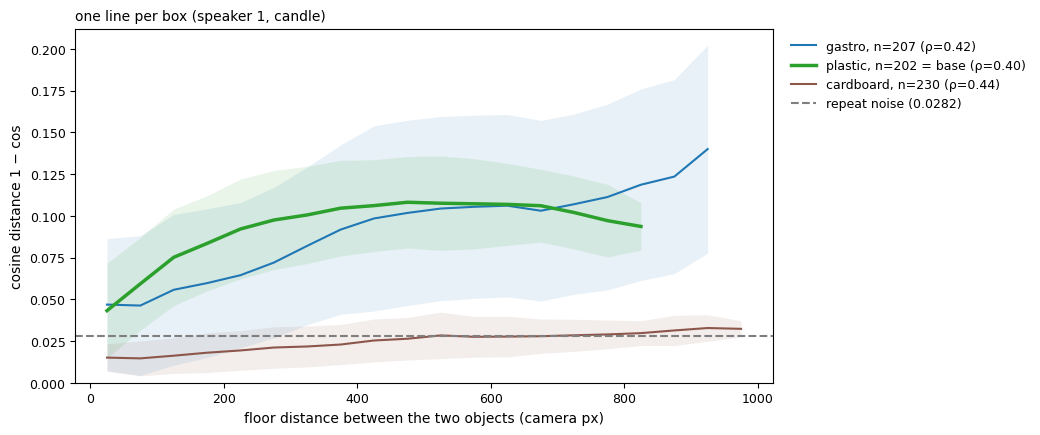

saved figures/src/data_analysis/distance/distance_object.svg


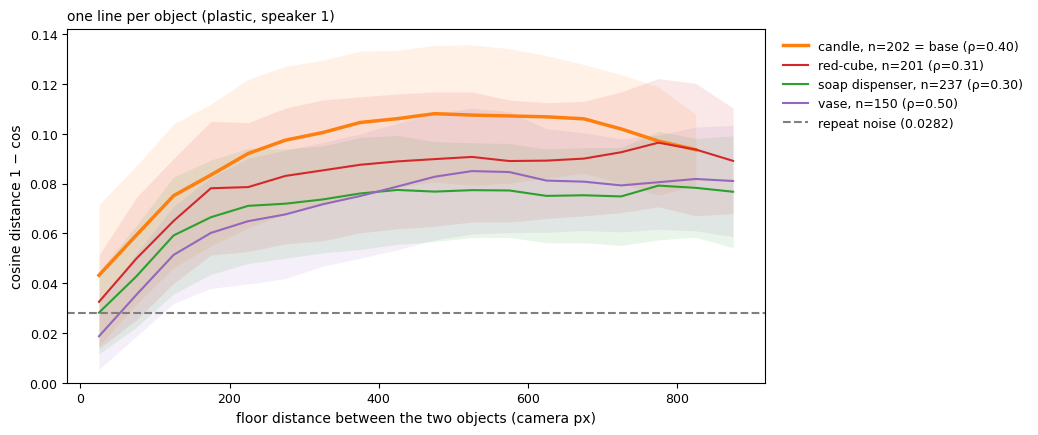

saved figures/src/data_analysis/distance/distance_speaker.svg


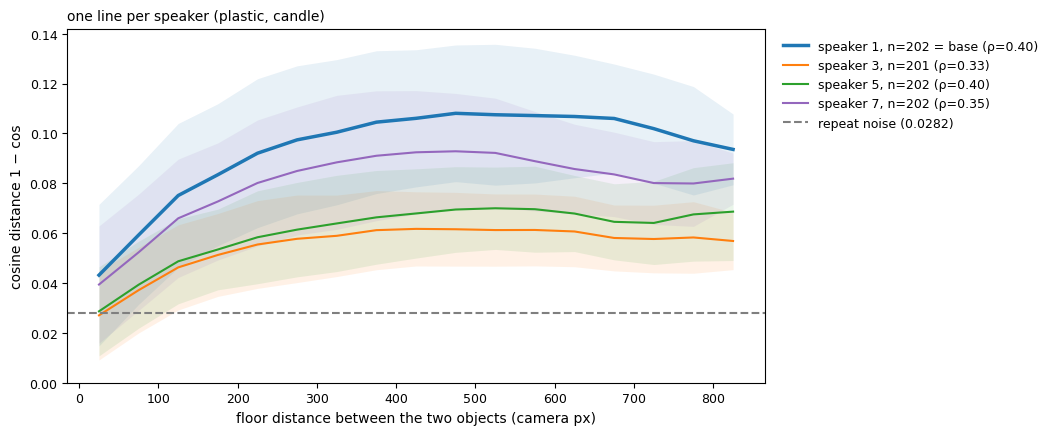

binned mean d in units of repeat noise:
 figure           line  first_bin  max_bin  px_at_max  last_bin
    all           base        1.5      3.8      475.0       3.3
    all            box       22.0     22.9      925.0      22.9
    all         object        2.3      3.6      675.0       3.4
    all        speaker        6.9      7.7      625.0       7.5
    box         gastro        1.7      5.0      925.0       5.0
    box        plastic        1.5      3.8      475.0       3.3
    box      cardboard        0.5      1.2      925.0       1.1
 object         candle        1.5      3.8      475.0       3.3
 object       red-cube        1.2      3.4      775.0       3.2
 object soap dispenser        1.0      2.8      775.0       2.7
 object           vase        0.7      3.0      525.0       2.9
speaker      speaker 1        1.5      3.8      475.0       3.3
speaker      speaker 3        1.0      2.2      425.0       2.0
speaker      speaker 5        1.0      2.5      525.0       2.4


In [15]:
DIST_LEVELS = {
    "box": [(b, group(box=b), style.BOX_COLORS[b]) for b in BOXES],
    "object": [(o, group(objects=o), style.OBJECT_COLORS[o]) for o in TRAIN_OBJECTS],
    "speaker": [(f"speaker {s}", group(spk=s), style.SPEAKER_COLORS[s]) for s in TRAIN_SPEAKERS],
}
DIST_TITLES = {
    "box": f"one line per box (speaker {SPEAKER}, {OBJECT})",
    "object": f"one line per object ({BOX}, speaker {SPEAKER})",
    "speaker": f"one line per speaker ({BOX}, {OBJECT})",
}
for factor, levels in DIST_LEVELS.items():
    fig, ax = plt.subplots(figsize=(9, 4.6))
    for label, g, color in levels:
        x, y = within(g)
        is_base = label in [BOX, OBJECT, f"speaker {SPEAKER}"]
        DIST_CURVES[(factor, label)] = line(ax, x, y, color, f"{label}, n={len(g)}" + (" = base" if is_base else ""), lw=style.LW_BASE if is_base else style.LW)
    finish(ax, DIST_TITLES[factor])
    save(fig, f"distance/distance_{factor}")
    plt.show()

DIST_TABLE = pd.DataFrame([
    dict(figure=f, line=l, first_bin=c["mean"].iloc[0] / NOISE, max_bin=c["mean"].max() / NOISE, px_at_max=c.px.iloc[int(np.argmax(c["mean"].values))], last_bin=c["mean"].iloc[-1] / NOISE)
    for (f, l), c in DIST_CURVES.items()
])
print("binned mean d in units of repeat noise:")
print(DIST_TABLE.round(1).to_string(index=False))

**Reading §3**
- **Base (plastic, speaker 1, candle)**: d rises from **1.5×** noise at 0–50 px to a maximum of **3.8×** at 475 px, then falls slightly (3.3× at 825 px). Spearman **ρ = 0.40** over all pairs. The nearest bin is still above the noise line.
- **Changing a factor adds a floor that position cannot reach.** Change box: **22.0–22.9×**, flat in floor distance (ρ = −0.02). Change speaker: **6.9 → 7.7×** (ρ = 0.07). Change object: **2.3 → 3.6×** (ρ = 0.27). It sits on the base curve beyond ~200 px, so objects are indistinguishable once positions differ by more than that.
- **Per box** (speaker 1, candle): gastro rises the whole way (**1.7 → 5.0×** at 925 px, ρ = 0.42); plastic flattens at ~475 px; cardboard is flat and below the plastic noise line (**0.5 → 1.2×**, ρ = 0.44). Its curve tops out at about a third of plastic's (1.2 vs 3.8×), though its rank order is as clean.
- **Per object** (plastic, speaker 1): all four rise and flatten the same way. Maxima are **2.8–3.8×**; vase has the highest ρ (**0.50**), soap dispenser the lowest (**0.30**).
- **Per speaker** (plastic, candle): speaker 1 has the largest position contrast (max **3.8×**), then 7 (**3.3×**), 5 (**2.5×**) and 3 (**2.2×**). ρ is 0.33–0.40. How well position shows in the input depends on where the speaker is.

## 4 · Floor coverage

Where each object was recorded, per box: every capture's object centre(s) over the empty-box photo, train vs eval (the run's split;
`unused` captures left out). One dot per floor position (all speakers record the same spot); counts = captures (positions in brackets). Speakers are drawn at their wall positions
(`record/record.ipynb`). The outline in the middle is one capture's segmentation mask of that object, moved to the box centre,
for scale. Multi-object scenes plot both object centres.

multi-object scenes (train + eval captures): {'green-cube+red-cube': 923, 'red-cube+vase': 580}


saved figures/src/data_analysis/floor_coverage/floor_all.svg


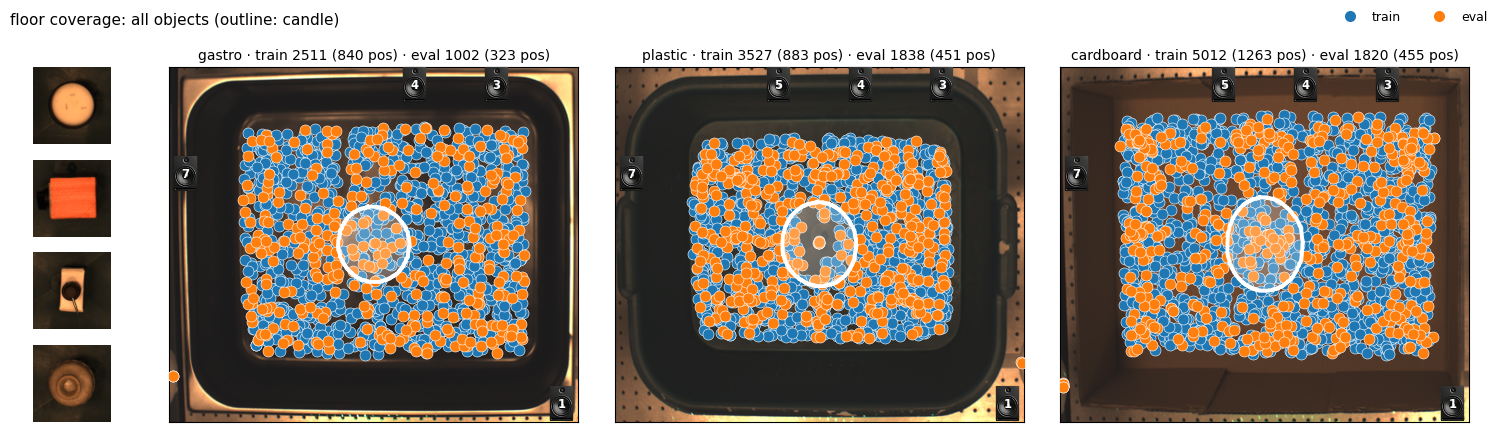

saved figures/src/data_analysis/floor_coverage/floor_candle.svg


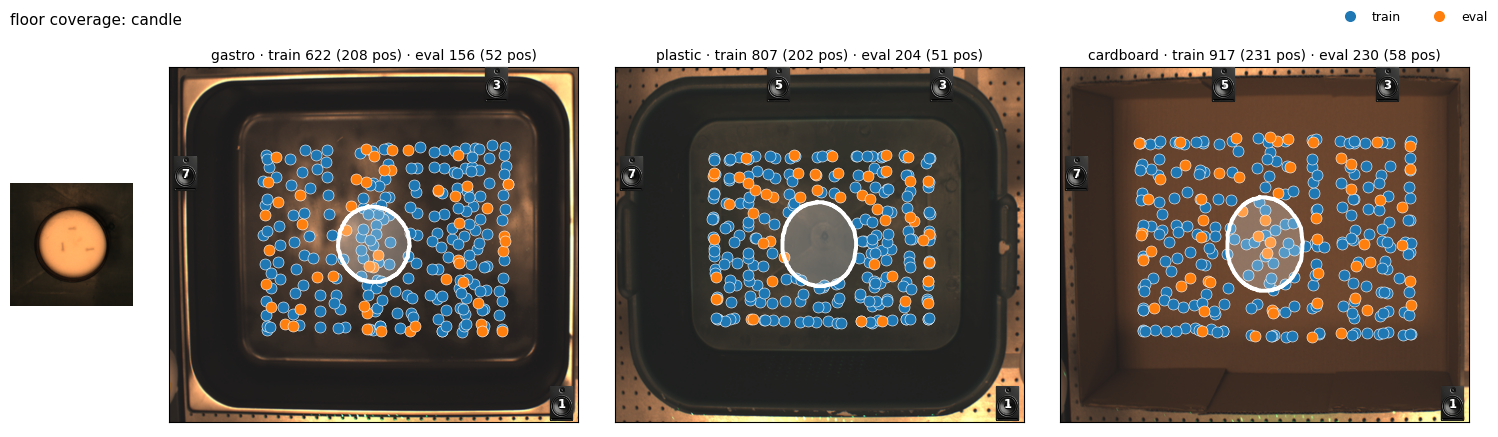

saved figures/src/data_analysis/floor_coverage/floor_red-cube.svg


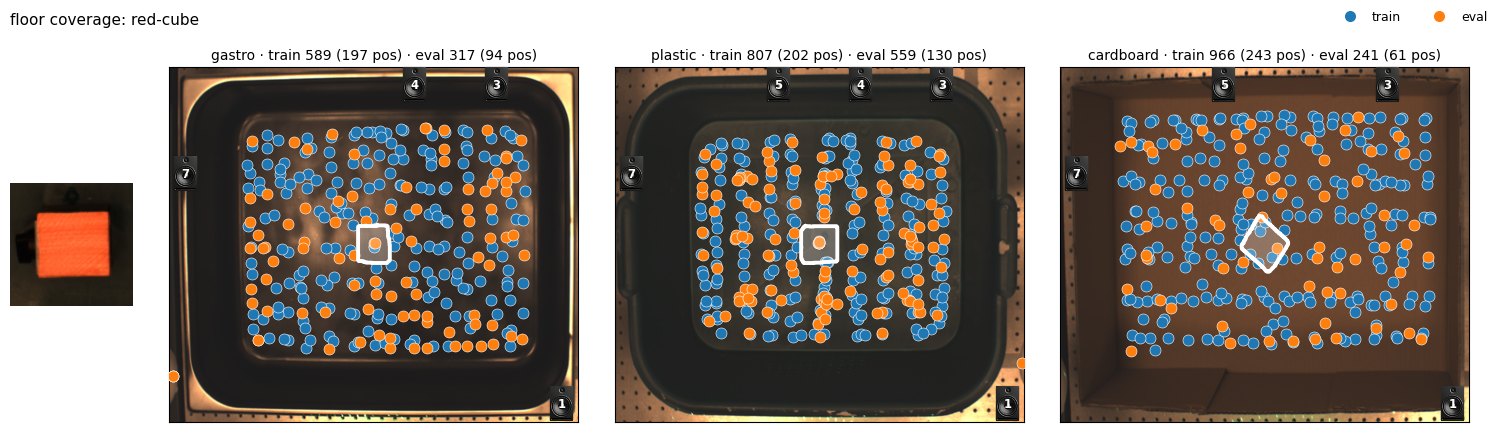

saved figures/src/data_analysis/floor_coverage/floor_soap_dispenser.svg


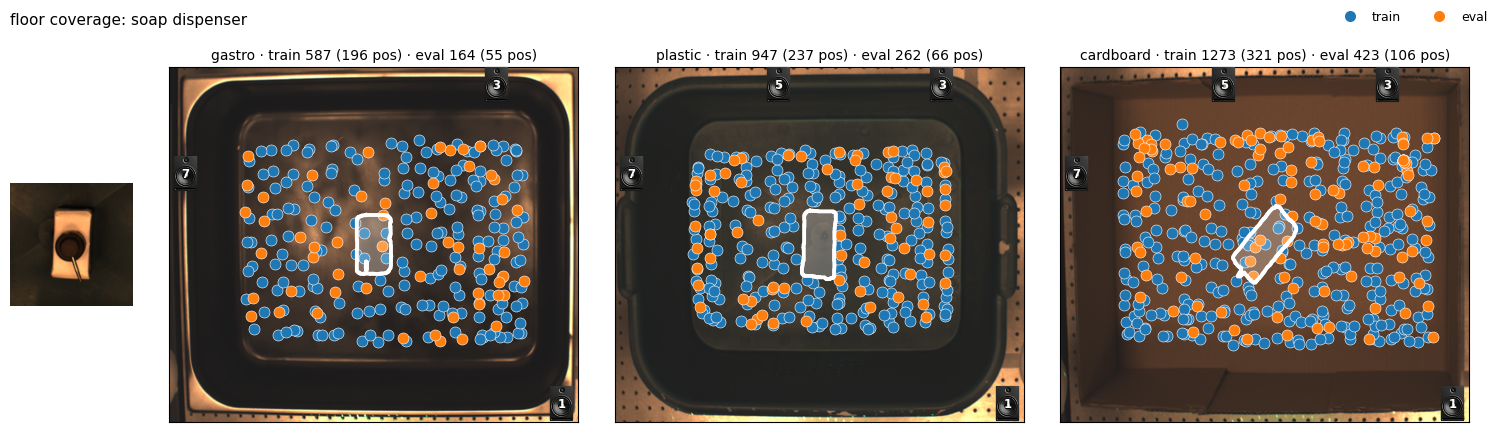

saved figures/src/data_analysis/floor_coverage/floor_vase.svg


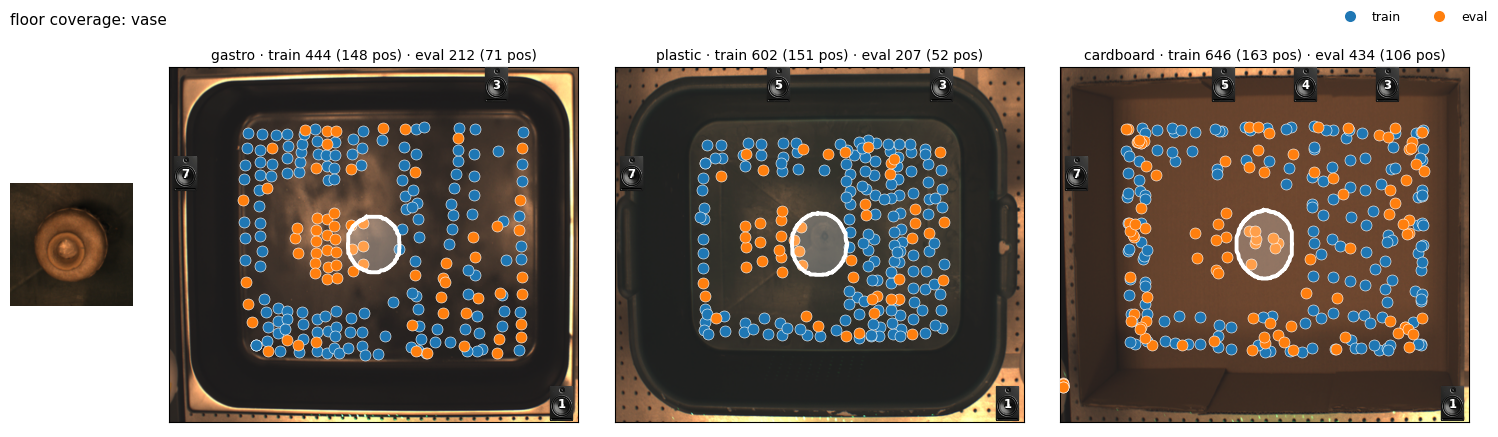

saved figures/src/data_analysis/floor_coverage/floor_coffee_pot.svg


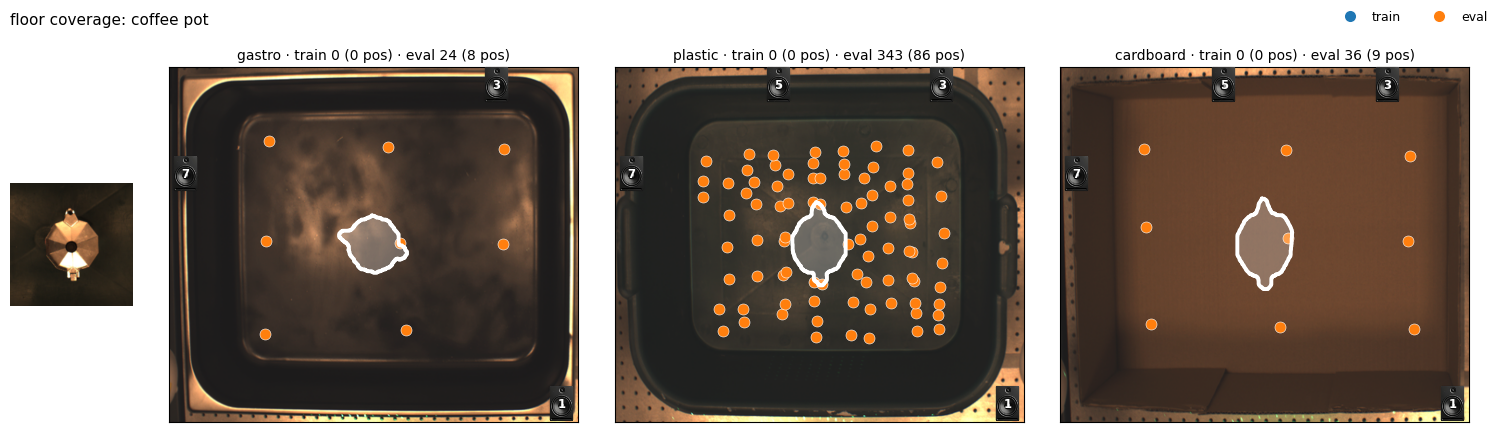

saved figures/src/data_analysis/floor_coverage/floor_tomato_sauce.svg


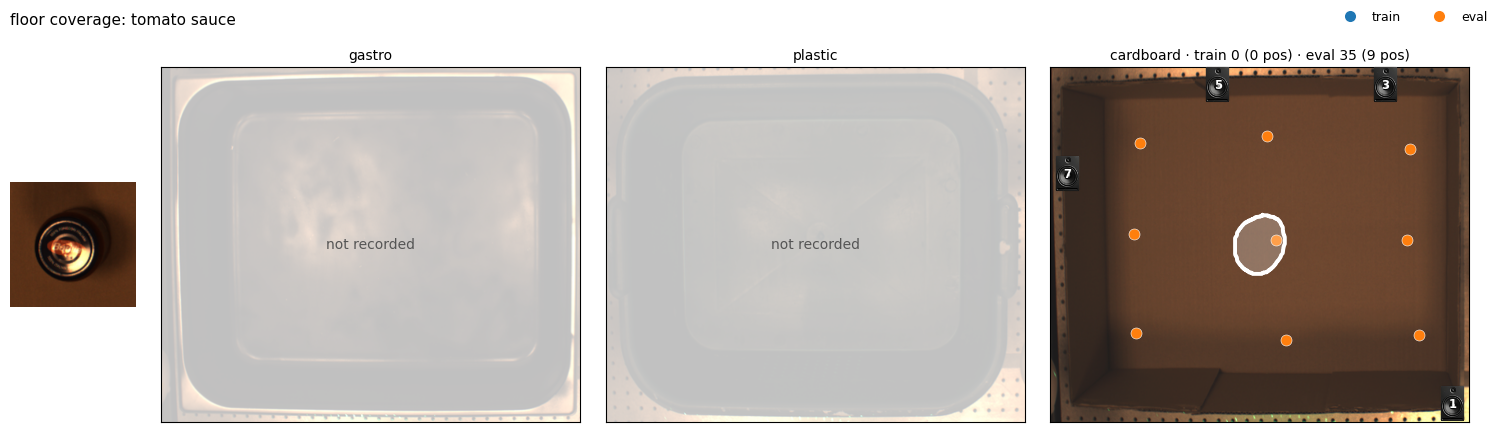

saved figures/src/data_analysis/floor_coverage/floor_green-cube_and_red-cube.svg


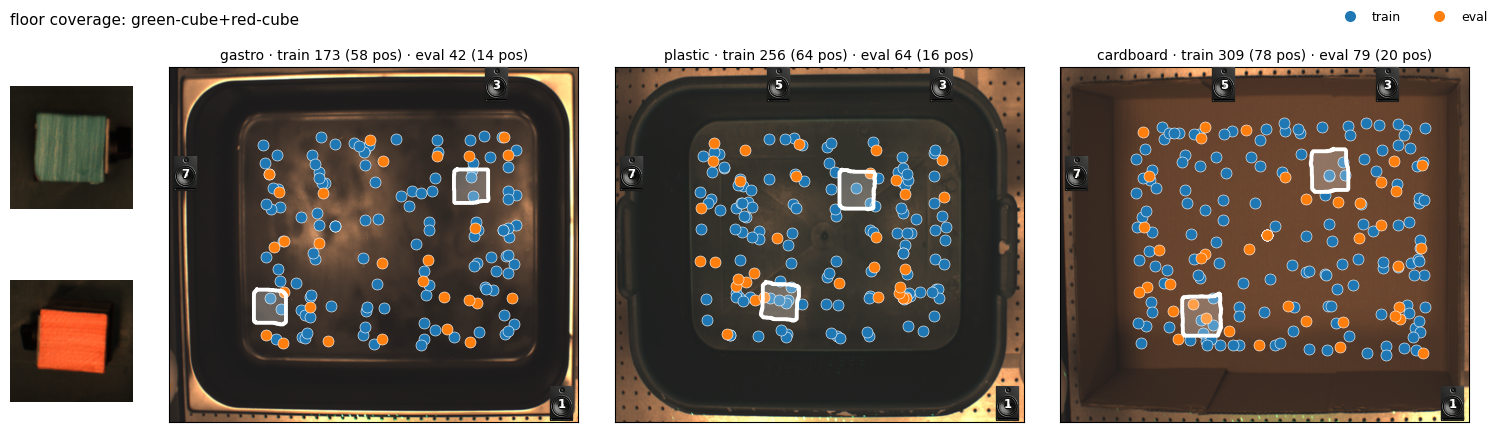

saved figures/src/data_analysis/floor_coverage/floor_red-cube_and_vase.svg


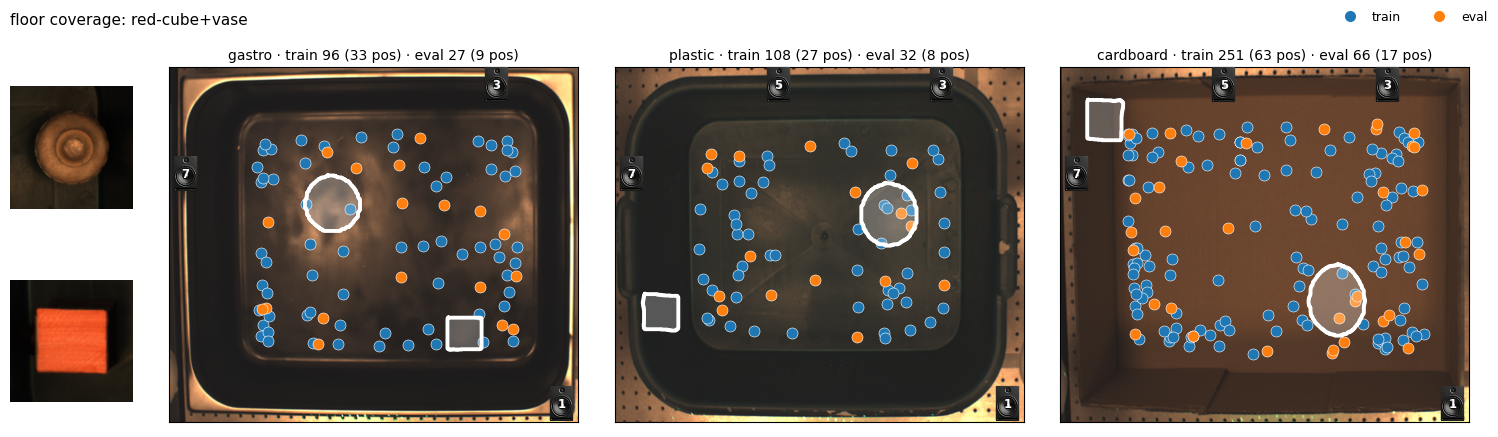

box                 cardboard       gastro       plastic      
kind                     eval train   eval train    eval train
objects                                                       
candle                    230   917    156   622     204   807
red-cube                  241   966    317   589     559   807
soap dispenser            423  1273    164   587     262   947
vase                      434   646    212   444     207   602
coffee pot                 36     0     24     0     343     0
tomato sauce               35     0      0     0       0     0
green-cube+red-cube        79   309     42   173      64   256
red-cube+vase              66   251     27    96      32   108


In [16]:
MULTI = META[META.objects.str.contains("+", regex=False) & (META.kind != "unused")].objects.value_counts()
print("multi-object scenes (train + eval captures):", MULTI.to_dict())
MULTI_OBJECTS = ["green-cube+red-cube", "red-cube+vase"]   # cube+cube and cube+vase
assert all(m in MULTI.index for m in MULTI_OBJECTS)
COVERAGE_OBJECTS = TRAIN_OBJECTS + UNSEEN_OBJECTS + MULTI_OBJECTS
DOT_SIZE = 63   # scatter area in pt^2: 3x the diameter of the old s=7 dots
SPEAKER_POSITION = {1: (1, 0), 2: (1, 0.7), 3: (0.8, 1), 4: (0.6, 1), 5: (0.4, 1), 6: (0.2, 1), 7: (0, 0.7), 8: (0, 0)}  # record/record.ipynb: (x, y), y = 0 at the bottom
SPEAKER_IMAGE = np.asarray(Image.open(ROOT / "assets/speaker.png").convert("RGBA").resize((96, 96), Image.LANCZOS))

def outline(objects, box):
    """contour(s) of one capture's mask, in box fractions, moved so the mask centre sits at the box centre"""
    d, mask = central_sample(objects, box)
    H, W = mask.shape
    rr, cc = np.where(mask)
    cs = plt.contour(mask.astype(float), levels=[0.5])
    polygons = [v for p in cs.get_paths() for v in p.to_polygons()]   # one polygon per object outline
    cs.remove()
    return [np.column_stack([v[:, 0] / W - cc.mean() / W + 0.5, v[:, 1] / H - rr.mean() / H + 0.5]) for v in polygons if len(v) > 5]

def coverage_panel(ax, box, objects):
    """objects = an object name, or None for every non-empty scene"""
    g = META[(META.box == box) & (META.kind != "unused") & (META.objects != "empty")]
    if objects is not None:
        g = g[g.objects == objects]
    has_data = len(g) > 0
    ax.imshow(BOX_PHOTO[box], extent=(0, 1, 1, 0), aspect="auto", alpha=0.9 if has_data else 0.25)
    texts = []
    for kind in ["train", "eval"]:
        k = g[g.kind == kind]
        one_per_position = k.drop_duplicates(["exp", "pos"])   # the 4 speakers record the same spot: one dot per floor position
        pts = np.array([p for coms in one_per_position.coms for p in coms]).reshape(-1, 2)
        ax.scatter(pts[:, 1], pts[:, 0], s=DOT_SIZE, color=style.SPLIT_COLORS[kind], edgecolor="white", linewidth=0.4, zorder=3)
        texts.append(f"{kind} {len(k)} ({k.groupby(['exp', 'pos']).ngroups} pos)")
    if has_data:
        contour_object = OBJECT if objects is None else objects
        contour_box = box if (META[(META.box == box)].objects == contour_object).any() else None
        for v in outline(contour_object, contour_box):
            ax.fill(v[:, 0], v[:, 1], color="white", alpha=0.25, lw=0, zorder=4)
            ax.plot(v[:, 0], v[:, 1], color="white", lw=2.8, zorder=5)
        for s in sorted(g.spk.unique()):
            x, y = SPEAKER_POSITION[s]
            xy = (np.clip(x, 0.04, 0.96), np.clip(1 - y, 0.05, 0.95))
            style.thumbnail(ax, SPEAKER_IMAGE, xy, size=0.45)
            ax.text(xy[0], xy[1], str(s), ha="center", va="center", fontsize="small", color="white", fontweight="bold", zorder=7)
        ax.set_title(f"{box} · " + " · ".join(texts))
    else:
        ax.text(0.5, 0.5, "not recorded", ha="center", va="center", color=style.MUTED, transform=ax.transAxes)
        ax.set_title(box)
    ax.set_xlim(0, 1)
    ax.set_ylim(1, 0)
    ax.set_xticks([])
    ax.set_yticks([])

def scene_photos(objects):
    """photo crops of the object(s) in a scene: one per object; a multi-object scene is cut per mask blob of one capture"""
    if "+" not in objects:
        d, mask = central_sample(objects, BOX)
        return [object_crop(d, mask)]
    d, mask = central_sample(objects, BOX)
    blobs, n = ndimage.label(mask)
    sizes = ndimage.sum(mask, blobs, range(1, n + 1))
    biggest = np.argsort(-sizes)[:2] + 1
    return [object_crop(d, blobs == k) for k in biggest]

def coverage_figure(objects, name):
    photos = [OBJECT_PHOTO[o] for o in TRAIN_OBJECTS] if objects is None else scene_photos(objects)
    fig = plt.figure(figsize=(style.WIDE, 4.4))
    gs = fig.add_gridspec(1, 4, width_ratios=[0.3, 1, 1, 1])
    left = gs[0, 0].subgridspec(len(photos), 1)
    for k, image in enumerate(photos):
        pax = fig.add_subplot(left[k, 0])
        pax.imshow(image)
        pax.axis("off")
    axes = [fig.add_subplot(gs[0, j + 1]) for j in range(3)]
    for ax, b in zip(axes, BOXES):
        coverage_panel(ax, b, objects)
    title = "all objects" if objects is None else objects
    handles = [plt.Line2D([], [], marker="o", ls="none", color=style.SPLIT_COLORS[k], mec="white", ms=9, label=k) for k in ["train", "eval"]]
    fig.legend(handles=handles, loc="upper right", ncol=2, frameon=False)
    fig.suptitle(f"floor coverage: {title}" + ("" if objects is not None else f" (outline: {OBJECT})"), x=0.01, ha="left")
    fig.tight_layout()
    save(fig, f"floor_coverage/{name}")
    return fig

coverage_figure(None, "floor_all")
plt.show()
for o in COVERAGE_OBJECTS:
    fig = coverage_figure(o, "floor_" + o.replace(" ", "_").replace("+", "_and_"))
    plt.show()

COVERAGE_TABLE = META[(META.kind != "unused") & META.objects.isin(COVERAGE_OBJECTS)].pivot_table(index="objects", columns=["box", "kind"], values="i", aggfunc="count", fill_value=0)
print(COVERAGE_TABLE.reindex(COVERAGE_OBJECTS).to_string())

**Reading §4**
- Train / eval captures per box (gastro / plastic / cardboard). Candle **622 / 156**, **807 / 204**, **917 / 230**. Red-cube **589 / 317**, **807 / 559**, **966 / 241**. Soap dispenser **587 / 164**, **947 / 262**, **1,273 / 423**. Vase **444 / 212**, **602 / 207**, **646 / 434**.
- All objects together: gastro **2,511 train (840 positions) / 1,002 eval (323)**, plastic **3,527 (883) / 1,838 (451)**, cardboard **5,012 (1,263) / 1,820 (455)**. Eval positions are spread through the whole floor grid, mixed with train.
- Unseen objects are eval only. Coffee pot: **24 / 343 / 36** captures; plastic holds 85% of them. Tomato sauce: **35**, cardboard only, on 9 positions.
- Multi-object scenes: green-cube+red-cube **173+42 / 256+64 / 309+79** (train+eval), red-cube+vase **96+27 / 108+32 / 251+66**. Both are train *and* eval, and they cover the whole floor.
- Speakers: drawn per panel from the captures shown. Gastro has 1/3/7 plus the unseen speaker 4 (cube eval only), plastic and cardboard 1/3/5/7. Speaker 4 also appears in cardboard (vase, 28 eval).

## 5 · Resonance peak: a box property

Each box has one dominant low resonance that changing the speaker, object or position does not move. Numbers on every train
capture of the 4 train objects, all train speakers, all positions, all boxes: peak = argmax of the capture's laser-averaged z|X|
in 120–260 Hz at full resolution (0.77 Hz bins). Figure: top = the three boxes' base curves (speaker 1, candle, train); below,
columns = boxes, rows = the one factor that changes at that box's base (train speakers, the 4 floor regions, the 4 train
objects). Black line = argmax of the box's base mean curve; shaded band = ± half the smallest gap between box lines.
Curves on raw bins (no smoothing); each dot = the top of the curve inside the shown window.

In [17]:
# laser-averaged curves of every train capture of the 4 train objects (all speakers, all boxes), cached
ALL = META[(META.kind == "train") & META.objects.isin(TRAIN_OBJECTS)].reset_index(drop=True)
all_index = CACHE / "curves_all_index.parquet"
all_file = CACHE / "curves_all.npy"
cached_all = pd.read_parquet(all_index) if all_index.exists() else None
if cached_all is None or set(cached_all.dir) != set(ALL.dir):
    curves_all = np.zeros((len(ALL), len(FREQ)), np.float32)
    for k, d in enumerate(ALL.dir):
        curves_all[k] = CURVES[ROW[d]] if d in ROW else features(d, samples[Path(d)]).mean((0, 2))
    np.save(all_file, curves_all)
    ALL[["dir"]].to_parquet(all_index)
    cached_all = ALL[["dir"]]
curves_all = np.load(all_file)
CURVE_OF = dict(zip(cached_all.dir, curves_all))
ALL["peak"] = [peak_hz(CURVE_OF[d]) for d in ALL.dir]
print(len(ALL), "captures")

def mean_curve(g):
    return np.mean([CURVE_OF[d] for d in g.dir], 0)

BOX_PEAK = ALL.groupby("box").peak.median().reindex(BOXES)
SPK_PEAK = ALL.groupby(["box", "spk"]).peak.median().unstack().reindex(BOXES)
OBJ_PEAK = ALL.groupby(["box", "objects"]).peak.median().unstack().reindex(BOXES)[TRAIN_OBJECTS]
BASE_ALL = {b: ALL[(ALL.box == b) & (ALL.spk == SPEAKER) & (ALL.objects == OBJECT)] for b in BOXES}
REGION_PEAK = pd.DataFrame({b: {name: peak_hz(mean_curve(BASE_ALL[b][BASE_ALL[b].region == name])) for name in REGION_NAMES} for b in BOXES})
RES_TABLE = pd.DataFrame({
    "box median Hz": BOX_PEAK,
    "max shift speakers": SPK_PEAK.max(axis=1) - SPK_PEAK.min(axis=1),
    "max shift objects": OBJ_PEAK.max(axis=1) - OBJ_PEAK.min(axis=1),
    "max shift regions": REGION_PEAK.max() - REGION_PEAK.min(),
})
print(RES_TABLE.round(1).to_string())
print("speaker medians:\n", SPK_PEAK.round(1).to_string())
print("region peaks (mean curve per region):\n", REGION_PEAK.round(1).to_string())
print(f"{BOX}: per-capture peaks by region\n", BASE_ALL[BOX].groupby("region").peak.describe()[["count", "25%", "50%", "75%"]].round(1).to_string())

nearest_box = np.array(BOXES)[np.argmin(np.abs(ALL.peak.values[:, None] - BOX_PEAK.values[None, :]), axis=1)]
print(f"captures whose peak is nearest their own box's median: {np.mean(nearest_box == ALL.box.values):.3f} (n={len(ALL)})")
print("per box:", {b: round(float(np.mean(nearest_box[ALL.box.values == b] == b)), 3) for b in BOXES})

# the argmax can hop between a box's fixed resonances: per box, the 3 most frequent peak frequencies (>= 4 Hz apart)
for b in BOXES:
    pk = ALL[ALL.box == b].peak.values
    vals, counts = np.unique(pk, return_counts=True)
    modes = []
    for v in vals[np.argsort(-counts)]:
        if all(abs(v - m) >= 4 for m in modes):
            modes.append(float(v))
        if len(modes) == 3:
            break
    on_mode = np.min(np.abs(pk[:, None] - np.array(modes)[None, :]), axis=1) <= 2.0
    print(f"{b}: top peaks {' / '.join(f'{m:.1f}' for m in modes)} Hz; captures within ±2 Hz of one of them: {on_mode.mean():.3f}")

9207 captures
           box median Hz  max shift speakers  max shift objects  max shift regions
gastro             186.2                 0.0                0.0                0.0
plastic            157.7                 3.8                0.8               53.1
cardboard          176.2                 4.6                0.0                0.0
speaker medians:
 spk            1      3      5      7
box                                  
gastro     186.2  186.2    NaN  186.2
plastic    158.5  158.5  157.7  154.6
cardboard  176.9  176.9  176.2  172.3
region peaks (mean curve per region):
               gastro  plastic  cardboard
top-left       186.2    211.5      176.9
top-right      186.2    158.5      176.9
bottom-left    186.2    158.5      176.9
bottom-right   186.2    158.5      176.9
plastic: per-capture peaks by region
               count    25%    50%    75%
region                                  
bottom-left    18.0  158.5  158.5  180.6
bottom-right   23.0  158.5  158.5  194.6


box line (base mean-curve argmax): {'plastic': 158.46, 'cardboard': 176.92, 'gastro': 186.15} band ±4.62 Hz


saved figures/src/data_analysis/resonance/resonance_peak.svg


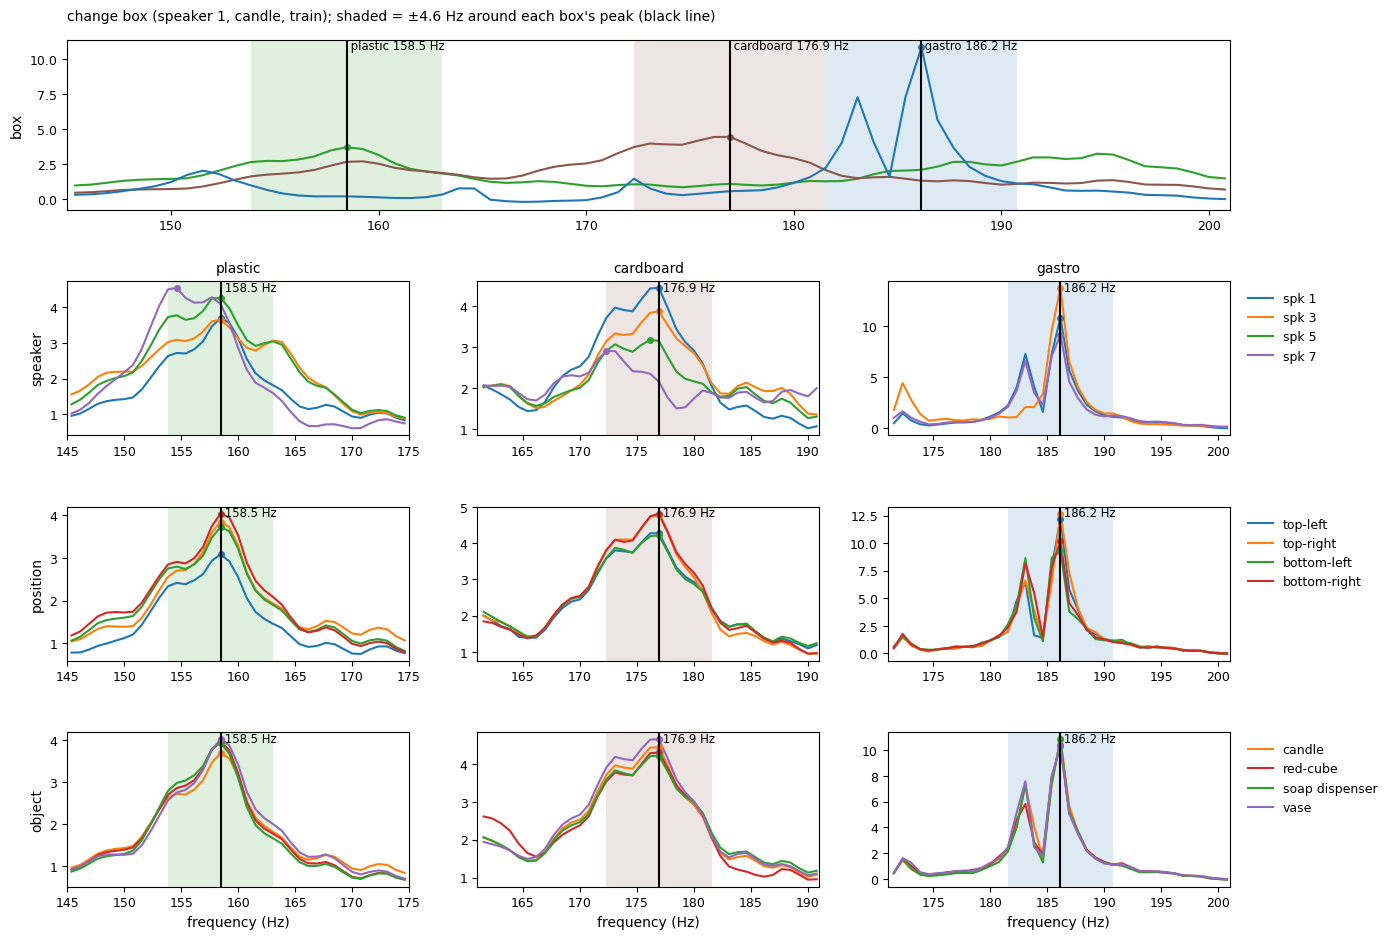

pairwise box-line gaps (Hz): {'plastic-cardboard': np.float64(18.46), 'plastic-gastro': np.float64(27.69), 'cardboard-gastro': np.float64(9.23)}
max |in-window peak - box line| per factor (Hz):
box       cardboard  gastro  plastic
row                                 
object          0.0     0.0      0.0
position        0.0     0.0      0.0
speaker         4.6     0.0      3.8
curves inside the ±4.62 Hz band: 35/35 (in-window), 34/35 (global 120-260 Hz argmax)
dots within one FFT bin (0.77 Hz) of their line: 36 of 38
curves whose global argmax is outside their band:
         row      box     level  window_peak  global_peak  delta_window  delta_global
14  position  plastic  top-left        158.5        211.5           0.0          53.1


In [18]:
RES_BOXES = ["plastic", "cardboard", "gastro"]   # ascending peak
RES_XLIM = {"plastic": (145.0, 175.0), "cardboard": (161.0, 191.0), "gastro": (171.0, 201.0)}   # equal 30 Hz spans
BOX_LINE = pd.Series({b: peak_hz(mean_curve(BASE_ALL[b])) for b in RES_BOXES})
BAND_HZ = float(np.diff(np.sort(BOX_LINE.values)).min()) / 2   # bands of neighbouring boxes touch, never overlap
print("box line (base mean-curve argmax):", BOX_LINE.round(2).to_dict(), f"band ±{BAND_HZ:.2f} Hz")

RES_ROWS = {   # factor -> box -> [(label, captures, colour)]
    "speaker": {b: [(f"spk {s}", ALL[(ALL.box == b) & (ALL.spk == s) & (ALL.objects == OBJECT)], style.SPEAKER_COLORS[s]) for s in sorted(ALL[ALL.box == b].spk.unique())] for b in RES_BOXES},
    "position": {b: [(name, BASE_ALL[b][BASE_ALL[b].region == name], style.POSITION_COLORS[name]) for name in REGION_NAMES] for b in RES_BOXES},
    "object": {b: [(o, ALL[(ALL.box == b) & (ALL.spk == SPEAKER) & (ALL.objects == o)], style.OBJECT_COLORS[o]) for o in TRAIN_OBJECTS] for b in RES_BOXES},
}

def band(ax, b, label=""):
    ax.axvspan(BOX_LINE[b] - BAND_HZ, BOX_LINE[b] + BAND_HZ, color=style.BOX_COLORS[b], alpha=0.15, lw=0, zorder=0)
    ax.axvline(BOX_LINE[b], color=style.MEDIAN_COLOR, lw=style.LW, zorder=4)
    ax.text(BOX_LINE[b], 1.0, f" {label}{BOX_LINE[b]:.1f} Hz", transform=ax.get_xaxis_transform(), fontsize="small", va="top", ha="left", zorder=5)

def curve_with_dot(ax, m, color, lo, hi):
    keep = (FREQ >= lo) & (FREQ <= hi)
    ax.plot(FREQ[keep], m[keep], color=color, lw=style.LW, zorder=2)
    k = int(np.argmax(np.where(keep, m, -np.inf)))
    ax.plot(FREQ[k], m[k], marker="o", ms=4, color=color, ls="none", zorder=3)
    return float(FREQ[k])

WINDOW_PEAKS = []
fig = plt.figure(figsize=(style.WIDE, 11))
gs = fig.add_gridspec(4, 3, height_ratios=[1.1, 1, 1, 1], hspace=0.45)
ax = fig.add_subplot(gs[0, :])
lo = RES_XLIM["plastic"][0]
hi = RES_XLIM["gastro"][1]
for b in RES_BOXES:
    band(ax, b, label=f"{b} ")
    m = mean_curve(BASE_ALL[b])
    WINDOW_PEAKS.append(dict(row="box", box=b, level=b, window_peak=curve_with_dot(ax, m, style.BOX_COLORS[b], lo, hi), global_peak=peak_hz(m)))
ax.set_xlim(lo, hi)
ax.set_ylabel("box")
ax.set_title(f"change box (speaker {SPEAKER}, {OBJECT}, {SPLIT}); shaded = ±{BAND_HZ:.1f} Hz around each box's peak (black line)", loc="left", pad=14)
for i, factor in enumerate(RES_ROWS):
    for j, b in enumerate(RES_BOXES):
        ax = fig.add_subplot(gs[i + 1, j])
        lo, hi = RES_XLIM[b]
        band(ax, b)
        for label, g, color in RES_ROWS[factor][b]:
            m = mean_curve(g)
            WINDOW_PEAKS.append(dict(row=factor, box=b, level=label, window_peak=curve_with_dot(ax, m, color, lo, hi), global_peak=peak_hz(m)))
        ax.set_xlim(lo, hi)
        if i == 0:
            ax.set_title(b)
        if j == 0:
            ax.set_ylabel(factor)
        if i == len(RES_ROWS) - 1:
            ax.set_xlabel("frequency (Hz)")
        if j == len(RES_BOXES) - 1:
            levels = {}
            for bb in RES_BOXES:
                for label, _, c in RES_ROWS[factor][bb]:
                    levels[label] = c
            labels = sorted(levels) if factor == "speaker" else list(levels)
            handles = [plt.Line2D([], [], color=levels[label], lw=style.LW, label=label) for label in labels]
            ax.legend(handles=handles, loc="upper left", bbox_to_anchor=(1.02, 1.0), frameon=False)
save(fig, "resonance/resonance_peak")
plt.show()

WINDOW_PEAKS = pd.DataFrame(WINDOW_PEAKS)
WINDOW_PEAKS["delta_window"] = WINDOW_PEAKS.window_peak - WINDOW_PEAKS.box.map(BOX_LINE)
WINDOW_PEAKS["delta_global"] = WINDOW_PEAKS.global_peak - WINDOW_PEAKS.box.map(BOX_LINE)
factor_peaks = WINDOW_PEAKS[WINDOW_PEAKS.row != "box"]
print("pairwise box-line gaps (Hz):", {f"{a}-{b}": round(abs(BOX_LINE[a] - BOX_LINE[b]), 2) for a, b in itertools.combinations(RES_BOXES, 2)})
print("max |in-window peak - box line| per factor (Hz):")
print(factor_peaks.assign(a=factor_peaks.delta_window.abs()).groupby(["row", "box"]).a.max().unstack().round(1).to_string())
print(f"curves inside the ±{BAND_HZ:.2f} Hz band: {int((factor_peaks.delta_window.abs() <= BAND_HZ).sum())}/{len(factor_peaks)} (in-window), "
      f"{int((factor_peaks.delta_global.abs() <= BAND_HZ).sum())}/{len(factor_peaks)} (global 120-260 Hz argmax)")
print(f"dots within one FFT bin ({DF:.2f} Hz) of their line: {int((WINDOW_PEAKS.delta_window.abs() <= DF + 1e-6).sum())} of {len(WINDOW_PEAKS)}")
print("curves whose global argmax is outside their band:")
print(WINDOW_PEAKS[WINDOW_PEAKS.delta_global.abs() > BAND_HZ].round(1).to_string())

**Reading §5**
- **Contrast: changing the box moves the resonance by at least 9.2 Hz; changing anything else moves it by at most 4.6 Hz.**
  - Black line = argmax of each box's base mean curve: **plastic 158.5, cardboard 176.9, gastro 186.2 Hz**. The lines are **9.2 Hz** apart for cardboard–gastro, **18.5 Hz** for plastic–cardboard and **27.7 Hz** for plastic–gastro.
  - Median over all **9,207** train captures (4 objects, all train speakers, all positions): **plastic 157.7, cardboard 176.2, gastro 186.2 Hz**. **91.1%** of captures peak nearest their own box's median (gastro 98.5%, plastic 90.1%, cardboard 87.5%).
- Inside the shown window the peak moves away from the line by at most (plastic / cardboard / gastro): speaker **3.8 / 4.6 / 0.0 Hz**, region **0 / 0 / 0 Hz**, object **0 / 0 / 0 Hz**.
- The band is **±4.6 Hz**, half the smallest gap between lines. All **35** speaker / region / object curves peak inside their band within the window. On the global 120–260 Hz argmax the count is **34 / 35**. **36 of 38** dots are within one FFT bin (0.77 Hz) of their line; the exceptions are speaker 7 in plastic (−3.9 Hz) and cardboard (−4.6 Hz).
- The one global exception is plastic's **top-left region (211.5 Hz)**. Its per-capture median is **195.4 Hz** (IQR 185.6–211.5), against **158.5 Hz** for the other regions. In plastic, position changes *which* of the box's fixed resonances is loudest (**158.5 / 153.8 / 211.5 Hz** hold **92.7%** of captures within ±2 Hz), not where they are.
- Cardboard's and gastro's top peaks hold **98.9%** and **96.3%** of their captures. The resonance frequencies are set by the box.